# Private-company comparables and valuation

Qual2Cast | Rational AI | 20 October 2026 | Preliminary research memo

The five-part memo summarizes the whole team's evidence. The contribution register and the complete reproducible workflow follow.


<h2>1. Research question and main finding</h2>
<p>Can company websites and a small set of supplied financials identify defensible public comparables and support an initial valuation of a private business? We built and tested a workflow that retrieves candidates, checks business compatibility, compares permitted financial factors and estimates an EV/EBITDA multiple. <b>Text matching has not yet improved valuation over a simple baseline:</b> on 535 public-company stand-ins, MPNet cosine matching produced 34.7% median absolute percentage error, versus 34.6% for the median of all other companies. Our newer business-review stage makes peer selection traceable and can abstain, but its default pilot valued only two of ten targets. These are preliminary public-company experiments, not validation of private-company fair value. [1,3]</p>
<h2>2. Data and assumptions</h2>
<p><b>Sources and populations.</b> The sponsor supplied 560 US public companies with Capital IQ identifiers, websites, SIC codes and financial fields. The fixed <i>company_list_v3</i> snapshot corrects website addresses and SIC zero-padding; the source financials are unchanged. The original matching run used 535 companies with eligible text, re-parsed on 18 October 2026. The integrated evidence policy dated 19 October retains 538. These populations differ because their preparation policies differ; we report them separately. Website text is partial coverage of each company, not a complete business census. [1,3]</p>
<p><b>Development cases.</b> The integrated run uses PCTY, BV, ROAD, FIX, BRO, ADUS, LOPE, ODFL, WING and DXPE. These were chosen to expose differences in business model, sparse peer coverage and unusual multiples; they are not a random sample. Earlier work also used a combined 19-company pilot. Neither set is held out. Riya supplied pre-output Paylocity peer labels; those labels do not cover all ten companies or validate the newer review stage. [1-3]</p>
<p><b>Permitted inputs.</b> A private target supplies its name and website and, when available, LTM revenue, LTM EBITDA and debt. LTM means the latest twelve months. Revenue, EBITDA margin and debt/revenue are optional secondary factors after business compatibility, not assumed publicly observable for a private company. Target stock data, investor-relations pages and observed EV/EBITDA are excluded from matching. Public-peer multiples enter only after peer selection; the public target's multiple is revealed only for scoring. Company names may remain in text, so the integrated experiment is not fully identity-blind. [3,6]</p>
<p><b>Time and measurement.</b> The supplied multiples' valuation dates and EBITDA definitions remain unconfirmed. Recent website captures are not point-in-time historical inputs. The current scores therefore describe a snapshot exercise, not a historical backtest. Public-comp 10-K enrichment and cross-vendor Orbis/Preqin joins are permitted future inputs but are not part of this frozen matching experiment. [3,6]</p>

<h2>3. Analytical approach and rationale</h2>
<p><b>Collect and represent the whole observed business.</b> The website pipeline retains URLs, capture times and filtering records. The team's collection work includes financial/ticker filters, blocked-page checks and name-masking experiments. The integrated workflow extracts source-backed activities, customers and operating roles without selecting only a convenient business line. Sentence evidence is a non-LLM alternative. Quotes establish where a claim came from; they do not establish that the interpretation is correct. Missing activities or segment weights remain unknown. [2,3]</p>
<p><b>Retrieve candidates.</b> The baseline splits text into 200-word chunks, averages MPNet embeddings and ranks by cosine similarity. A within-target z-score cutoff selects unusually similar candidates. It can still select a wrong business when the entire pool is weak. Mutual nearest neighbours, UMAP/HDBSCAN and hierarchical clustering test whether reciprocal or group structure helps. TF-IDF, LSA and reciprocal rank fusion (RRF) provide lexical, reduced-dimension and combined alternatives. RRF sums 1/(60 + rank) across rankings; it is not a probability. Kethan's separate SIC experiment expands industry groups and constructs candidate pools; its subsequent ranking and comparative evaluation are unfinished. SIC is a diagnostic alternative, not sufficient evidence of the same business. [1,3,5]</p>
<p><b>Review business fit before scale.</b> Source-bounded LLM review checks function, operating role, customer use and the full observed business scope. Direct, staged, few-shot and retrieved-evidence prompts are compared; all four criteria need support. This addresses recurring mismatches such as contractor versus equipment maker, broker versus insurer, and distributor versus manufacturer. It assumes the website contains enough evidence and the reviewer interprets it correctly. Independent human review is the reference alternative. Current automatic pass decisions are provisional. Retrieval-augmented review uses saved source sentences; it is not autonomous new 10-K collection. Fine-tuning is proposed, not completed. [3]</p>
<p><b>Compare factors and calculate a multiple.</b> After business review, compare revenue, EBITDA margin and debt/revenue individually and in combinations, against business-only ordering. Equal-weight percentile distances test factor subsets without fitting weights to ten known outcomes. Scale and profitability may matter economically, but periods, accounting definitions and leverage conventions must align. Median, harmonic, geometric and rank-weighted peer multiples are sensitivity alternatives; no universal winner is established. [3,6]</p>
<p><b>Valuation calculation.</b> For target <i>i</i>, let <i>C</i><sub>i</sub> contain selected public peers and let <i>M</i><sub>j</sub> be peer <i>j</i>'s positive EV/EBITDA multiple. The default is <b>M-hat<sub>i</sub> = median(M<sub>j</sub>: j in C<sub>i</sub>)</b>. Indicative enterprise value is <b>EV-hat<sub>i</sub> = M-hat<sub>i</sub> x supplied LTM EBITDA<sub>i</sub></b>. At least three eligible peers are required. Enterprise value is not equity value; a defensible equity bridge also needs cash, debt and other relevant claims. [3]</p>
<p><b>Keep growth evidence separate from a forecast.</b> The team collector extracts 13 event types from news, press and careers pages, including contracts, launches, hiring, layoffs, acquisitions and credit events. Rules, an LLM and their intersection are evaluated on the same articles. SEC EDGAR provides annual revenue for 518 companies and three-year outcome labels for 488 at a 2022 cutoff. Event history is too shallow to support that historical prediction exercise yet; events are not converted into an unsupported growth premium. [3,4]</p>

<h2>4. Results and interpretation</h2>
<p>Comparisons below keep the evaluation cases fixed within each row. The 535-company study, ten-company pilot and event-extraction study are separate experiments. The integrated pilot uses five reviewed candidates per target and selects three when enough pass. Its 672 configurations are repeated measurements on ten companies, not 6,720 independent tests. [1,3]</p>
<table><thead><tr><th>Evaluation cases</th><th>Metric</th><th>Baseline</th><th>Compared method</th><th>Status</th></tr></thead><tbody><tr><td>535 targets [1]</td><td>Median APE</td><td>No matching: 34.6%</td><td>MPNet z &gt;= 2: 34.7%</td><td>Reused snapshot; 535 estimates each</td></tr><tr><td>10 pilot targets [3]</td><td>Estimate coverage</td><td>No matching: 10/10</td><td>RRF + staged review: 2/10</td><td>Five candidates reviewed per target</td></tr><tr><td>PCTY + WING [3]</td><td>Median APE</td><td>No matching: 61.1%</td><td>RRF + staged review: 53.6%</td><td>Same 2 cases; selected by method</td></tr><tr><td>Same 2 cases [3]</td><td>Median APE</td><td>MPNet, no review: 41.9%</td><td>RRF + staged review: 53.6%</td><td>Not evidence that review improves error</td></tr><tr><td>145 pages / 10 firms [3,4]</td><td>Precision / recall</td><td>Rules: 58.1% / 42.9%</td><td>LLM: 56.7% / 90.5%</td><td>Reused single-annotator labels</td></tr><tr><td>Same 145 pages [3,4]</td><td>Precision / recall</td><td>Rules: 58.1% / 42.9%</td><td>Rules AND LLM: 81.8% / 42.9%</td><td>Same labels; agreement filter</td></tr></tbody></table>
<p><b>Metrics.</b> APE = 100 x |estimated multiple - observed multiple| / observed multiple; median APE is calculated only where an estimate exists. Coverage is estimated targets divided by attempted targets. Event precision = correct predicted article/type pairs divided by all predicted pairs; recall = correct pairs divided by the 42 labeled positive pairs. The 145 pages belong to ten companies, so they are not 145 independent company observations.</p>
<p><b>Valuation remains unresolved.</b> The original study's 0.1 percentage-point difference does not support a matching advantage. Its equal-count comparisons (3-10 peers) also failed to establish a consistently better alternative. In the new pilot, PCTY's error is 22.9%, but WING's is 84.4%. Their conditional median is 53.6%; using the same two cases, it is better than no matching but worse than unreviewed MPNet. Eight abstentions and two selected observations cannot establish superiority, reliability or private-company accuracy. [1,3]</p>
<p><b>Review depth and financial measurement matter.</b> A separate PCTY search reviewed 50 of 537 ranked candidates and automatically accepted PAYC, ASUR and ADP; 487 remained unreviewed. This demonstrates resumable search, not ten validated peers. For BrightView, a separate sourced EBITDA example produces $289.7m from four quarters and $289.8m from FY plus current YTD less prior YTD. Their $0.1m difference is consistent with reported rounding, but does not resolve issuer add-backs or validate every company's financial definition. [3]</p>
<p><b>Event extraction shows a measurable trade-off.</b> The LLM recovered 38 of 42 labeled positives versus 18 for rules: recall rose 47.6 percentage points, with precision down 1.3 points. Requiring agreement raised precision to 81.8% while retaining only 18 positives. False positives included board appointments treated as hiring and share sales treated as funding. These labels were originally held out for the team's rules, then reused in our LLM development; this comparison is not a fresh test and does not measure revenue prediction. [3,4]</p>

<h2>5. Limitations and next step</h2>
<p><b>Three limitations could change the conclusion.</b> First, peer relevance has not been independently validated across the new workflow. Existing Paylocity labels and historical profile audits are useful, but they are not labels for the new 112-pair comparison. All 324 recorded model judgments have provenance checks; they do not have independent correctness labels. Second, the candidate universe omits genuine competitors, and incomplete websites can conceal whole business lines. Low coverage may reflect retrieval depth, pool composition or review errors; the current experiment cannot separate these explanations. Third, unverified financial dates/definitions and short event histories prevent a credible historical valuation or three-year growth test. The EDGAR collection also flags 438 revenue observations across 211 companies for review. [2-4]</p>
<p><b>Next test: isolate the value of business review.</b> Select 20 additional public targets outside the 560-company development universe using a recorded sector sampling rule and seed, before viewing their valuation outcomes. This requires new collection and identity alignment; the current cached notebook cannot accept arbitrary new companies without that preparation. Freeze one dated source snapshot, the candidate universe, representation settings, prompt, review budget and minimum of three selected peers. Align the supplied target financials and public-peer financials to a documented valuation date and accounting basis before scoring.</p>
<p>For each new target, form one fixed candidate pool from the union of the top 20 MPNet and top 20 RRF candidates. Compare three arms on that same pool: MPNet ordering, RRF ordering, and RRF followed by staged business review. Keep financial reranking off and use the same median estimator, so changes can be attributed to retrieval order or business review. Two reviewers independently label the pooled pairs without seeing model decisions, scores or valuation errors, then adjudicate disagreements using source evidence.</p>
<p><b>Decision rule.</b> The primary endpoint is relevant peers among the three requested slots per target, with unfilled slots counted as zero; also report conditional precision and the number of targets with three defensible peers. Use paired target-level bootstrap intervals and show all company results. Retain staged review only if it improves the primary endpoint with a positive 95% paired interval and does not reduce human-confirmed three-peer coverage. Evaluate valuation error separately on common estimated cases, alongside coverage and the share of all targets valued within 25%. If the evidence is inconclusive, keep the simpler method and diagnose missing peers rather than tune on these test cases. This is a proposed protocol, not a completed result.</p>
<p><b>Reproducibility.</b> The accompanying notebook preserves the sequential workflow, per-method rationale and citations, code, recorded prompts/responses, source references and detailed results. Its last execution completed 17 code cells with zero errors and eight figures; 294 software tests passed. Those checks establish implementation and replay consistency, not economic validity. The repository appendix records individual contributions and completed versus proposed work. No fresh inference is needed to reproduce the saved experiment. [3]</p>
<div class="sources"><b>Evidence references</b><br>[1] <a href="https://github.com/Qual2Cast/Qual2Cast/blob/0ec1aa1/matching/README.md">Team matching methods and all-company evaluation</a><br>[2] <a href="https://github.com/Qual2Cast/Qual2Cast/blob/0ec1aa1/conversations/2026-10-18-riya-branch-integration.md">Riya's collection and peer-label integration</a><br>[3] <a href="https://github.com/Qual2Cast/Qual2Cast/blob/0ec1aa1/reports/team_company_workflow/README.md">Integrated workflow, recorded results and validation</a><br>[4] <a href="https://github.com/Qual2Cast/Qual2Cast/blob/0ec1aa1/conversations/2026-10-19-growth-signals.md">Growth rules, held-out evaluation and SEC revenue coverage</a><br>[5] <a href="https://github.com/Qual2Cast/Qual2Cast/blob/9c9d77b1edaaa0a6e203a972971ab8f46bb91e7c/sic_method/README.md">Kethan's SIC-first experiment (separate branch)</a><br>[6] <a href="https://github.com/Qual2Cast/Qual2Cast/blob/0ec1aa1/reports/team_company_workflow/field_selection.csv">Field selection and private-target availability</a></div>

<h2>Appendix A. Team contributions and integration status</h2>
<p>This register combines the 19 October team progress document, project-group updates and repository artifacts checked on 20 October. It records supported contributions, not a ranking of effort. It is not a claim that every branch is executed by the integrated notebook. The submitted update identifies six code contributors; additional discussion and coordination are distinguished below. No separate completed artifact for Yiming Zhu was identified in those sources; contribution attribution remains open rather than inferred.</p>
<table><thead><tr><th>Contributor</th><th>Work included</th><th>Verified status</th><th>Source</th></tr></thead><tbody><tr><td>Michael Chen</td><td>Snapshot correction, full website collection, MPNet/mutual/clustering/tree matching, all-company and ten-target evaluation; earlier profile extractor.</td><td>Implemented; main. Historical profile audit is distinct from new peer-review labels.</td><td><a href="https://github.com/Qual2Cast/Qual2Cast/blob/0ec1aa1/matching/README.md">Repository source</a></td></tr><tr><td>Riya Mhatre</td><td>Scraper filters and masking, initial TF-IDF/LSA/embedding comparisons, pre-output Paylocity peer labels.</td><td>Filters/methods ported; original branch retained. Labels cover one target, not the new full pilot.</td><td><a href="https://github.com/Qual2Cast/Qual2Cast/blob/0ec1aa1/conversations/2026-10-18-riya-branch-integration.md">Repository source</a></td></tr><tr><td>Fiona (Xiaozhe) Shao</td><td>Dated 13-type growth extraction, hand-labeled evaluation and error analysis; SEC annual revenue and outcome construction.</td><td>Integrated into main. Revenue anomaly review and historical event coverage remain incomplete.</td><td><a href="https://github.com/Qual2Cast/Qual2Cast/blob/0ec1aa1/conversations/2026-10-19-growth-signals.md">Repository source</a></td></tr><tr><td>Kethan Bethamcharla</td><td>OSHA SIC industry-group expansion and same-SIC candidate pools; the team update reports 54 SIC4 and 83 SIC3 candidates for PCTY.</td><td>Implemented on kethan/wip; later within-pool ranking/evaluation unfinished. Not an executed arm in the integrated notebook.</td><td><a href="https://github.com/Qual2Cast/Qual2Cast/blob/9c9d77b1edaaa0a6e203a972971ab8f46bb91e7c/sic_method/README.md">Repository source</a></td></tr><tr><td>Yifan (Richard) Chen</td><td>Initial website-description collection for the 38-company SIC 35 sample.</td><td>Earlier collection incorporated into the team&#x27;s broader website work.</td><td><a href="https://github.com/Qual2Cast/Qual2Cast/blob/0ec1aa1/conversations/2026-10-17-task3-profile-pipeline.md">Repository source</a></td></tr><tr><td>Eric (Yikai) Li</td><td>Ten-company pilot, combined 19-company notebook, modular workflow, alternative retrieval/review/factor/valuation methods, growth comparison, EBITDA example and review forms.</td><td>PR #6 merged. Frozen replay and tests complete; independent review, private-company validation and growth forecasting incomplete.</td><td><a href="https://github.com/Qual2Cast/Qual2Cast/blob/0ec1aa1/reports/team_company_workflow/README.md">Repository source</a></td></tr><tr><td>Barbara (Haoyan) Bai</td><td>Clarified sponsor input permissions and discussed LLM/10-K comparables and valuation direction.</td><td>Requirements/design contribution observed in project messages; no separately verified comparative valuation result is claimed.</td><td></td></tr><tr><td>Matthew Pisinski</td><td>Project discussion, source-permission clarification and review of the submitted team update.</td><td>Coordination/review contribution; no separate evaluated model is attributed.</td><td></td></tr></tbody></table>
<h2>Appendix B. Evidence and reproduction map</h2>
<p><b>Original all-company experiment.</b> Source [1] contains the original methods, same-SIC/no-matching controls, equal-count comparisons, bootstrap analysis and ten case studies. Runs: 20261019T080322Z and 20261019T080416Z. The published source is preserved; its 535-company results are reported, not recomputed by this editorial build.</p>
<p><b>Earlier team evidence.</b> Riya's pre-output labels, collection changes and historical profile audits are documented in [2]. They are neither superseded by an empty review template nor evidence that the new model decisions were independently graded. The original 19-company analysis remains in <i>notebooks/integrated_company_analysis.ipynb</i> and its matching reports directory. It showed development sensitivity to financial reranking, not a confirmed improvement.</p>
<p><b>Paylocity relevance check.</b> The original 535-company page-text run in [2] reported embedding NDCG@20 of 0.85 and recall@25 of 0.91 against Riya's labels, versus NDCG@20 of 0.80 and recall@25 of 0.64 for its combined score. Random ordering had NDCG@20 of 0.03. A later masked-input run used 534 companies and reported embedding NDCG@20 of 0.90; it is a different input snapshot. These one-target results concern retrieval relevance, not out-of-sample valuation accuracy.</p>
<p><b>Integrated experiment.</b> Run 20261020T033357Z-f5389a uses private-evidence-2026-10-19-v4. Its 672 configurations cross nine retrieval methods, review alternatives, eight factor choices and four aggregators, with smaller few-shot/RAG arms. Exact arm coverage is saved in comparison_scope.json; not every possible method combination was run. The 6,720 rows, prompts, responses and source modules are embedded in the notebook. The new compact table is recomputed from unreviewed_controls.csv and combination_results.csv for the integrated pilot; the all-company row is transcribed from pinned source [1].</p>
<p><b>Financial fields.</b> The 15-row field_selection.csv specifies purpose, target/peer side and availability. Explicitly supplied LTM revenue, EBITDA and debt may be used; stock-based target features are not required. Public-peer 10-K descriptions, database crosswalks and WRDS Ask AI are potential extensions, not completed integrations. Capital IQ identifiers do not imply a verified Orbis/Preqin identifier mapping.</p>
<p><b>Growth and labels.</b> Source [4] preserves the team's original held-out sequence and EDGAR outcome construction. The notebook's rules/LLM/intersection comparison uses 145 held-out-C pages later inspected during development. It scores article/type pairs, not exact event counts, forecast errors or economic value. The broader event evaluation includes sources beyond the narrow private-target deployment policy; its accuracy does not establish private-target source coverage. In the current ten targets, eligible ordinary-site growth evidence covers only PCTY, BV and WING.</p>
<p><b>Reproduce.</b> Use Python 3.12+ and pipeline/requirements-replay.txt. Download team_company_workflow.ipynb and run its code cells in order. It extracts its checksum-bound bundle into a local directory, replays recorded inference and recomputes downstream results without downloading a model. Source-level integration instructions are in pipeline/TEAM_WORKFLOW.md. Kethan's separate experiment requires its branch and source access. No teammate's original notebook or shared Google Doc was rewritten for this memo.</p>
<p><b>Team progress source.</b> <a href="https://docs.google.com/document/d/1fLsMKBPJ3IY-4UubZt9luw3Eutd8y_ftm_v367AbnUY/edit">Qual2Cast: Team Progress Check, 19 October 2026</a>. Its results are reconciled with the newer merged workflow; an unverified proposal is not reported as completed work.</p>
<div class="sources"><b>Evidence references</b><br>[1] <a href="https://github.com/Qual2Cast/Qual2Cast/blob/0ec1aa1/matching/README.md">Team matching methods and all-company evaluation</a><br>[2] <a href="https://github.com/Qual2Cast/Qual2Cast/blob/0ec1aa1/conversations/2026-10-18-riya-branch-integration.md">Riya's collection and peer-label integration</a><br>[3] <a href="https://github.com/Qual2Cast/Qual2Cast/blob/0ec1aa1/reports/team_company_workflow/README.md">Integrated workflow, recorded results and validation</a><br>[4] <a href="https://github.com/Qual2Cast/Qual2Cast/blob/0ec1aa1/conversations/2026-10-19-growth-signals.md">Growth rules, held-out evaluation and SEC revenue coverage</a><br>[5] <a href="https://github.com/Qual2Cast/Qual2Cast/blob/9c9d77b1edaaa0a6e203a972971ab8f46bb91e7c/sic_method/README.md">Kethan's SIC-first experiment (separate branch)</a><br>[6] <a href="https://github.com/Qual2Cast/Qual2Cast/blob/0ec1aa1/reports/team_company_workflow/field_selection.csv">Field selection and private-target availability</a></div>

# Technical appendix C. Reproducible company workflow
**Sequential workflow · Team development sample · 19 October 2026**

The objective is to analyze a private company using its name, website and explicitly supplied financial information. Public companies act as development targets; their observed valuation multiples are sealed until evaluation. The workflow proceeds from sample selection to evidence preparation, candidate retrieval, business review, financial factors, growth signals, EBITDA measurement, valuation and final evaluation.

The sponsor snapshot contains 560 companies; the versioned evidence policy retains 538. The ten team cases are purposive development examples. They do not establish accuracy on private companies or an independent test set. Every method returns its result and status, including missing evidence and abstention.

**Execution and structure.** Run cells in order with Python 3.12+ and `numpy`, `pandas`, `scipy`, `scikit-learn`, `matplotlib`, `requests`, `beautifulsoup4`, `jsonschema` and `threadpoolctl`. The notebook embeds the source modules, evidence, representations, exact model-response cache and reference results. It unpacks them into a checksum-specific local folder. Default execution performs no network request or model download; it recomputes the analysis while replaying recorded inference. Fresh model calls require an explicit live setting and the user's own authenticated CLI or API account.

The main interfaces are `TeamPipeline`, `PipelineConfig` and `ExperimentRunner`. Teammates add retrievers, factor methods or valuation methods through the corresponding stage's `register` function. The business gate remains mandatory after any retriever. Unknown companies require collection, identity alignment and a rebuilt representation bundle before this cached-corpus workflow can analyze them.

**Interpretation.** Website capture is partial, automatic review is fallible, and snapshot financial dates and definitions remain unverified. Company names can remain in retained source text; this is not a fully identity-blind experiment. Exact quotations constrain evidence attribution but do not prove semantic correctness or eliminate model-memory effects. Computed values are development proxies. Independent human judgments and point-in-time financial alignment are required before investment use.

**Navigation.** The numbered stages below describe execution order within this technical appendix; they are separate from the five sponsor-memo sections above. All existing method explanations, citations, code, numerical outputs and eight figures are retained. The original all-company and SIC-branch studies are linked in the team evidence map; this notebook does not claim to execute them.


In [1]:
PAYLOAD_BASE64 = '...'
PAYLOAD_SHA256 = '7868828a683ab9a452b9b99762b7b2d5e2c0907ea63fa185c812099f9e35205f'

In [2]:
import os
for variable in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS'):
    os.environ[variable] = '2'
from pathlib import Path
import base64, hashlib, io, json, sys, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
thread_limit = threadpool_limits(limits=2)
packed = base64.b64decode(PAYLOAD_BASE64)
assert hashlib.sha256(packed).hexdigest() == PAYLOAD_SHA256
WORK = Path.cwd() / ('company_workflow_' + PAYLOAD_SHA256[:12])
WORK.mkdir(exist_ok=True)
with zipfile.ZipFile(io.BytesIO(packed)) as archive:
    manifest = json.loads(archive.read('manifest.json'))
    for name, spec in manifest.items():
        destination = (WORK / name).resolve()
        if not destination.is_relative_to(WORK.resolve()):
            raise ValueError('Invalid archive path')
        data = archive.read(name)
        assert hashlib.sha256(data).hexdigest() == spec['sha256']
        if destination.exists() and hashlib.sha256(destination.read_bytes()).hexdigest() != spec['sha256']:
            raise ValueError('Existing extracted source differs: ' + name)
        if not destination.exists():
            destination.parent.mkdir(parents=True, exist_ok=True)
            destination.write_bytes(data)
sys.path.insert(0, str(WORK))
from pipeline.team import TeamPipeline, ExperimentRunner
from pipeline.stages import PipelineConfig
from pipeline.private_inputs import sponsor_simulation, private_financials, FACTOR_REGISTER
from pipeline.field_selection import FIELD_SELECTION
from pipeline.compare import run_comparison
from pipeline.reporting import export_reports
pipe = TeamPipeline.from_bundle(WORK / 'bundle', live_llm=False)
config = PipelineConfig(shortlist=5, peers=3, profile_method='llm', business_review_method='llm_staged',
                        llm_provider='cli', llm_model='gpt-6.1-sol', llm_revision=None)
comparison_config = config  # Preserve the declared fixed-budget reference experiment.
FIGURES = WORK / 'figures'
FIGURES.mkdir(exist_ok=True)
def show_figure(name):
    plt.tight_layout()
    plt.savefig(FIGURES / (name + '.png'), dpi=160, bbox_inches='tight')
    plt.show()
print(f'Verified {len(manifest)} embedded files; {len(pipe.workflow.ids)} eligible companies.')
print('Execution: cached model inference; downstream calculations recomputed.')

Verified 910 embedded files; 538 eligible companies.
Execution: cached model inference; downstream calculations recomputed.


## 1. Target selection
The primary sample retains the team's ten declared cases, allowing direct discussion of existing examples. A separate seeded sampler supports future experiments without selecting targets on observed valuation error. Its output below is a proposed next sample only; this report does not claim that it has received the full model and human evaluation.

**`team_pilot`.** Use the ten declared team development targets without relabeling them as random. Purposive diagnostic cases; no independent population inference.

Sources: [Cawley and Talbot (2010), On Over-fitting in Model Selection](https://www.jmlr.org/papers/v11/cawley10a.html)

**`seeded_random`.** Sample without replacement from eligible website records with a fixed seed and explicit exclusions. Random selection alone does not create a valid held-out test after repeated method tuning.

Sources: [Cawley and Talbot (2010), On Over-fitting in Model Selection](https://www.jmlr.org/papers/v11/cawley10a.html)

In [3]:
sample = pipe.sampling.run('team_pilot', pipe.workflow)
targets = sample['tickers']
company_rows = pipe.workflow.data.set_index('IQ_COMPANY_ID')
display(company_rows.loc[sample['company_ids'], ['target_ciq_ticker', 'target_company_name', 'target_ciq_website']])
print(sample['interpretation'])
next_sample = pipe.sampling.run('seeded_random', pipe.workflow, n=10, seed=4511,
                                exclude_ids=sample['company_ids'])
print('Proposed next sample, not evaluated:', ', '.join(next_sample['tickers']))
from pipeline.company import resolve_company
COMPANY_QUERY = 'https://www.paylocity.com'  # A name, ticker or website within the bundle.
resolution = resolve_company(pipe.workflow, COMPANY_QUERY)
if resolution['status'] != 'resolved':
    raise ValueError('Collect and align this company before running the cached-corpus workflow.')
identity = resolution['matches'][0]
company_id = identity['IQ_COMPANY_ID']
COMPANY = identity['target_ciq_ticker']

,target_ciq_ticker,target_company_name,target_ciq_website
IQ_COMPANY_ID,,,
IQ254957567,PCTY,Paylocity Holding Corporation,www.paylocity.com
IQ568706872,BV,"BrightView Holdings, Inc.",www.brightview.com
IQ5537074,ROAD,"Construction Partners, Inc.",www.constructionpartners.net
IQ100935,FIX,"Comfort Systems USA, Inc.",comfortsystemsusa.com
IQ297244,BRO,"Brown & Brown, Inc.",www.bbrown.com
IQ1108195,ADUS,Addus HomeCare Corporation,www.addus.com
IQ44732496,LOPE,"Grand Canyon Education, Inc.",www.gce.com
IQ319404,ODFL,"Old Dominion Freight Line, Inc.",www.odfl.com
IQ260824267,WING,Wingstop Inc.,wingstop.com


Purposive team development cases; not a random or independent holdout.
Proposed next sample, not evaluated: ALG, MRMD, TKR, LW, IMKT.A, SLGN, STRA, SMPL, FONR, DFIN


## 2. Evidence preparation and permitted inputs
The website layer preserves source URLs, capture timestamps, retained text, content hashes and the removal ledger. Investor-relations pages, detected public-market statements, blocked pages and explicit error-page titles are excluded. These rules reduce leakage; they cannot prove that the remaining website covers every activity or is factually complete.

The target's revenue, EBITDA and debt are optional explicit inputs. They are not retrieved secretly from the public target's financial table. This development experiment calls a visibly named `sponsor_simulation` adapter to imitate supplied figures. The target's EV/EBITDA is never an input to matching or extraction.

**`cached`.** Reuse versioned website captures; retain URLs, dates, text hashes and a removal ledger. Captured pages do not establish complete business coverage.

Sources: [Team website collection implementation](https://github.com/Qual2Cast/Qual2Cast/tree/4d24050a6eeedad5581ec91a8bf32b2821d0fbe3/website_scrape)

**`live_http`.** Run the existing robots-aware HTTP collector and save a new capture before transformation. Not rerun in the common-input experiment; dynamic or blocked pages may be unavailable.

Sources: [Team website collection implementation](https://github.com/Qual2Cast/Qual2Cast/tree/4d24050a6eeedad5581ec91a8bf32b2821d0fbe3/website_scrape)

,original_companies,eligible_companies,excluded_companies,policy
0,560,538,22,private-evidence-2026-10-19-v4


,source_id,source_url,fetched_at,eligible,text_sha256
0,IQ254957567:P1,https://www.paylocity.com/,2026-10-17T20:03:30Z,True,d0560606dc0dbda2274c26a62837514dcff58b69d4af0b...
1,IQ254957567:P2,https://www.paylocity.com/who-we-serve/,2026-10-17T20:03:34Z,True,465877a4b2ab4a5db905dcff4132cfa2f4a357731c291e...
2,IQ254957567:P3,https://www.paylocity.com/products/,2026-10-17T20:03:39Z,True,14b1033175ca9e49c711eb069c8833d50f6afa394e3b84...


,value,source_kind,source_ref,period_end,currency,units
revenue,1679.591000,sponsor_simulation,company_list_v3; simulates client-supplied fin...,None,None,source units
ebitda,380.790000,sponsor_simulation,company_list_v3; simulates client-supplied fin...,None,None,source units
debt,133.476999,sponsor_simulation,company_list_v3; simulates client-supplied fin...,None,None,source units


,factor,source,availability,use
0,Products/services and operating role,Company website / supplied business description,Potentially observable; evidence required,Mandatory business review
1,Customers and end markets,Explicit website statements,Conditional; unknown when absent,Business review
2,All observed business lines,Captured home/about/product/service pages,"Partial website coverage, not proven revenue c...",Scope review; no invented segment weights
3,Revenue model,Explicit pricing/contracts or client confirmation,Conditional,Review only when directly supported; no infere...
4,LTM revenue,Management accounts / client / authorized data...,Not assumed obtainable from a website,Optional size factor
5,LTM EBITDA,Management accounts or supplied reconciliation,Not assumed public; definition/period required...,Optional profitability factor and valuation de...
6,Debt,Supplied balance sheet / debt schedule,Not assumed public; gross/net definition matters,Optional debt/revenue factor
7,"EBITDA margin, debt/revenue",Derived from supplied inputs,Only if required inputs exist and revenue is p...,Optional secondary factors
8,"Stock price, market cap, beta, analyst forecas...",Public-market / classification data,Excluded from private-target matching,No target-side use; observed multiple is evalu...


,field,side,source,purpose,availability
0,Company name and website,Target and peer,User input; sponsor identity table,Resolve identity and locate evidence; not econ...,Required; new entities need collection and ali...
1,Products/services and operating role,Target and peer,Captured ordinary company website; exact sourc...,Distinguish actual function and position in th...,Extracted when supported; missing claims remai...
2,Customers and end uses,Target and peer,Explicit statements on captured website pages,Review whether the businesses serve comparable...,Conditional; customers' activities are not the...
3,All observed business activities,Target and peer,All retained source pages and activity profiles,Prevent cherry-picking one overlapping busines...,Observed scope only; segment revenue weights a...
4,Revenue model and pricing,Target and peer,Explicit website text or supplied business inf...,Support business-model review when directly do...,Conditional evidence; not a complete standardi...
5,LTM revenue,Target and peer,Target: supplied accounts; peer: authorized fi...,Optional scale comparison after business approval,Not assumed public for a private target; dates...
6,LTM EBITDA,Target and peer,Supplied accounts/reconciliation; authorized p...,Profitability measurement and target valuation...,Definition and period must be verified; no web...
7,Debt,Target and peer,Supplied debt schedule; authorized peer financ...,Optional financing-intensity comparison,Point-in-time balance; gross/net definition mu...
8,EBITDA margin and debt/revenue,Target and peer,Derived from aligned permitted financial inputs,Optional secondary factors; compare every subs...,Requires positive revenue and compatible inputs
9,"Growth events, event/publication date and sour...",Target and peer,"Ordinary news, press and careers pages","Describe recent activity; compare rules, LLM a...",Coverage is sparse; no validated forecast or v...


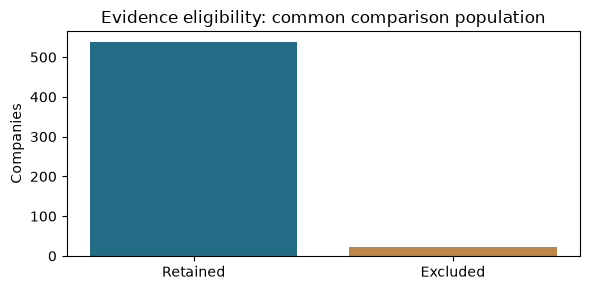

In [4]:
preparation = json.loads((WORK / 'bundle/preparation.json').read_text())
display(pd.DataFrame([{'original_companies': preparation['input_companies'],
                       'eligible_companies': preparation['retained_companies'],
                       'excluded_companies': len(preparation['excluded']),
                       'policy': preparation['policy']}]))
documents = [d for d in pipe.documents.values() if d['company_id'] == company_id]
display(pd.DataFrame(documents)[['source_id', 'source_url', 'fetched_at', 'eligible', 'text_sha256']])
financial_inputs = {t: sponsor_simulation(pipe.workflow, pipe.workflow.ticker[t]) for t in targets}
financial_inputs.setdefault(COMPANY, sponsor_simulation(pipe.workflow, company_id))
target_financials = private_financials(financial_inputs[COMPANY])
display(pd.DataFrame.from_dict(financial_inputs[COMPANY], orient='index'))
display(pd.DataFrame(FACTOR_REGISTER))
display(pd.DataFrame(FIELD_SELECTION))
assert private_financials()['values']['ebitda'] is None
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(['Retained', 'Excluded'], [preparation['retained_companies'], len(preparation['excluded'])], color=['#236c85', '#bd8847'])
ax.set(ylabel='Companies', title='Evidence eligibility: common comparison population')
show_figure('01_evidence_population')

### 2.1. Company activity representation
Profiles are evidence aids. A secondary business line remains part of the company even when only one activity resembles a peer. Source-backed statements about customers and partners must not be attributed to the company itself. No segment revenue shares are inferred from website word counts.

**`sentence_evidence`.** Retain all permitted source sentences without inferred facets. A source-evidence baseline, not an RBICS reconstruction.

Sources: [FactSet, RBICS with Tradenames](https://insight.factset.com/resources/at-a-glance-factset-rbics-with-tradenames-datafeed)

**`llm`.** Extract all observed activities, operating roles and customers; validate cited sentence IDs. Source traceability does not establish factual or scope completeness.

Sources: [Cao et al. (2025), Can generative AI help identify peer firms?](https://link.springer.com/article/10.1007/s11142-025-09892-6); [Qwen2.5-3B-Instruct model card](https://huggingface.co/Qwen/Qwen2.5-3B-Instruct)

In [5]:
reviewer, llm = pipe._reviewer(config)
profile = reviewer.profile(company_id)
display(pd.DataFrame(profile.get('activities', [])))
from matching.llm_methods import compact_cards, sentence_cards
cited = {sid for activity in profile.get('activities', []) for sid in activity['sentence_ids']}
profile_sources = [card for card in compact_cards(sentence_cards(pipe.documents, company_id), 'S') if card['sentence_id'] in cited]
display(pd.DataFrame(profile_sources)[['sentence_id', 'source_url', 'text']])
print('Profile status:', profile['status'])
print('Scope uncertainty:', profile.get('scope_uncertainties', ''))
print('Independent human verification:', profile.get('independent_human', False))

,description,role,customers,sentence_ids
0,"Provides a unified HCM platform connecting HR,...",Software platform provider,Organizations ranging from local businesses to...,"[S64, S71, S72, S73]"
1,"Provides recruiting, onboarding, benefits admi...",HR software provider,Employers and HR teams; POLYWOOD is a named on...,"[S41, S51, S77]"
2,Provides payroll processing and tax-filing too...,Payroll software and support provider; W-2 tra...,"Employers, payroll administrators, and employees.","[S6, S35, S43, S44]"
3,Provides employee engagement and mobile workpl...,Workplace software provider,"Employees, supervisors, and leaders.","[S48, S70, S77]"
4,"Provides headcount planning, expense managemen...",Finance software provider,Organizations and their HR and Finance teams.,"[S7, S29, S78]"
5,Offers Airbase by Paylocity corporate cards su...,Corporate card offering provider; issuing role...,Pilot Fiber is a named customer.,[S85]
6,"Provides IT tools for asset management, provis...",IT software provider,Organizational IT teams.,"[S8, S45, S79]"
7,Provides client service and support and works ...,Client support and solution partner,Paylocity clients.,"[S60, S74, S75]"


,sentence_id,source_url,text
0,S6,https://www.paylocity.com/,Simplify payroll and filing taxes with an intu...
1,S7,https://www.paylocity.com/,Transform spend management – real-time visibil...
2,S8,https://www.paylocity.com/,"Centralize asset management, access control, a..."
3,S29,https://www.paylocity.com/,Bring HR and Finance together to streamline op...
4,S35,https://www.paylocity.com/,Import your W-2 directly from Paylocity to one...
5,S41,https://www.paylocity.com/who-we-serve/,HR leaders are the champions of a thriving wor...
6,S43,https://www.paylocity.com/who-we-serve/,"Employees expect the right pay, every time, an..."
7,S44,https://www.paylocity.com/who-we-serve/,You need tools to simplify the process and lig...
8,S45,https://www.paylocity.com/who-we-serve/,IT is the guardian of a company's infrastructure.
9,S48,https://www.paylocity.com/who-we-serve/,"You need simple, but impactful solution to sta..."


Profile status: ok
Scope uncertainty: The evidence does not disclose revenue models, activity shares, or whether support and tailored systems work are separately sold. Corporate card issuance and underwriting roles are unknown. External tax preparers provide the destination services for W-2 imports; Paylocity's role in preparing individual tax returns is not established.
Independent human verification: False


## 3. Candidate matching against the larger dataset
Each target is excluded from its own candidate pool. Nine selectors operate on the same permitted text and population. Cosine is a representation-dependent geometric measure, not a probability of economic comparability. RRF combines ranks and therefore does not require cosine scales from different representations to be calibrated.

Michael's z-threshold, mutual-neighbor, cluster and hierarchy approaches are retained alongside the lexical, latent-semantic, embedding and fusion alternatives. Their output is a candidate list; business approval occurs in the next stage.

**`mpnet`.** Mean normalized MPNet embeddings of 200-word chunks; cosine ordering. Retrieval is a candidate proposal, not proof of comparable economics.

Sources: [Reimers and Gurevych (2019), Sentence-BERT](https://aclanthology.org/D19-1410/)

**`tfidf`.** Word unigrams/bigrams, sublinear term frequency and cosine ordering. Retrieval is a candidate proposal, not proof of comparable economics.

Sources: [Manning, Raghavan and Schuetze, Introduction to Information Retrieval](https://nlp.stanford.edu/IR-book/)

**`lsa`.** 96-component truncated SVD of TF-IDF, normalized before cosine ordering. Retrieval is a candidate proposal, not proof of comparable economics.

Sources: [scikit-learn: TruncatedSVD and latent semantic analysis](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html)

**`rrf`.** Fuse the three complete rankings with sum 1/(60 + rank). Retrieval is a candidate proposal, not proof of comparable economics.

Sources: [Cormack, Clarke and Buettcher (2009), Reciprocal Rank Fusion](https://research.google/pubs/reciprocal-rank-fusion-outperforms-condorcet-and-individual-rank-learning-methods/)

**`z2`.** Retain MPNet similarities at least two within-target standard deviations above their mean. Retrieval is a candidate proposal, not proof of comparable economics.

Sources: [Team matching implementation, Michael branch 14d7d95](https://github.com/Qual2Cast/Qual2Cast/tree/14d7d95749104100335f7a52152b39da265cbd58)

**`mutual20`.** Require reciprocal membership in the 20-nearest-neighbor lists. Retrieval is a candidate proposal, not proof of comparable economics.

Sources: [Team matching implementation, Michael branch 14d7d95](https://github.com/Qual2Cast/Qual2Cast/tree/14d7d95749104100335f7a52152b39da265cbd58)

**`cluster_eom`.** Use the team UMAP/HDBSCAN EOM membership selector, then order within the eligible group. Retrieval is a candidate proposal, not proof of comparable economics.

Sources: [Team matching implementation, Michael branch 14d7d95](https://github.com/Qual2Cast/Qual2Cast/tree/14d7d95749104100335f7a52152b39da265cbd58); [McInnes, Healy and Astels (2017), hdbscan](https://joss.theoj.org/papers/10.21105/joss.00205)

**`tree_complete`.** Complete-linkage hierarchy; select the smallest enclosing group with at least five peers. Retrieval is a candidate proposal, not proof of comparable economics.

Sources: [Team matching implementation, Michael branch 14d7d95](https://github.com/Qual2Cast/Qual2Cast/tree/14d7d95749104100335f7a52152b39da265cbd58); [scikit-learn: hierarchical clustering](https://scikit-learn.org/stable/modules/clustering.html#hierarchical-clustering)

**`tree_ward`.** Ward hierarchy on normalized embeddings; select the smallest enclosing group with at least five peers. Retrieval is a candidate proposal, not proof of comparable economics.

Sources: [Team matching implementation, Michael branch 14d7d95](https://github.com/Qual2Cast/Qual2Cast/tree/14d7d95749104100335f7a52152b39da265cbd58); [scikit-learn: hierarchical clustering](https://scikit-learn.org/stable/modules/clustering.html#hierarchical-clustering)

,method,peer,retrieval_rank,retrieval_score,measure
0,mpnet,PAYC,1,0.795532,mpnet_cosine
1,mpnet,ASUR,2,0.727421,mpnet_cosine
2,mpnet,ADP,3,0.724719,mpnet_cosine
3,mpnet,BBSI,4,0.694235,mpnet_cosine
4,mpnet,INTU,5,0.681972,mpnet_cosine
5,tfidf,BBSI,1,0.273439,tfidf_cosine
6,tfidf,ASUR,2,0.255101,tfidf_cosine
7,tfidf,ADP,3,0.245968,tfidf_cosine
8,tfidf,PAYC,4,0.244621,tfidf_cosine
9,tfidf,HURN,5,0.227480,tfidf_cosine


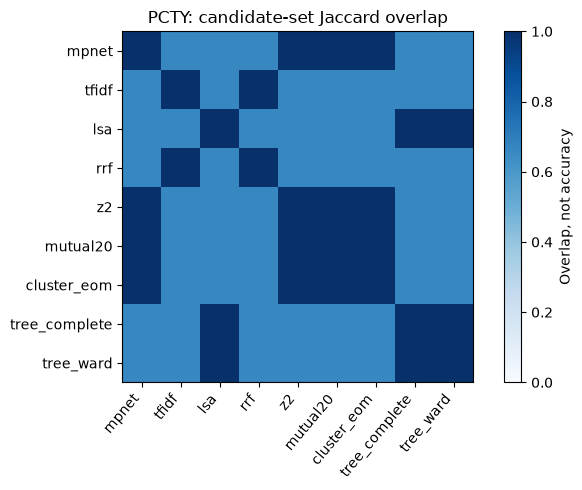

In [6]:
candidate_tables = {}
for method in pipe.matching.methods:
    candidate_tables[method] = pipe.matching.run(method, company_id=company_id, limit=config.shortlist)
candidate_results = pd.concat([frame.assign(method=method) for method, frame in candidate_tables.items()], ignore_index=True)
display(candidate_results[['method', 'peer', 'retrieval_rank', 'retrieval_score', 'measure']])
names = list(candidate_tables)
overlap = np.zeros((len(names), len(names)))
for i, left in enumerate(names):
    for j, right in enumerate(names):
        a, b = set(candidate_tables[left].peer_id), set(candidate_tables[right].peer_id)
        overlap[i, j] = len(a & b) / len(a | b) if a | b else np.nan
fig, ax = plt.subplots(figsize=(7, 5))
image = ax.imshow(overlap, vmin=0, vmax=1, cmap='Blues')
ax.set_xticks(range(len(names)), names, rotation=50, ha='right')
ax.set_yticks(range(len(names)), names)
ax.set_title(COMPANY + ': candidate-set Jaccard overlap')
fig.colorbar(image, ax=ax, label='Overlap, not accuracy')
show_figure('02_candidate_overlap')

## 4. Business comparability before financial ranking
The gate requires support for four criteria: actual business function, operating role, customer use and the whole observed scope. An equipment manufacturer does not become a service contractor because both mention HVAC. A broker is not an insurer merely because both serve the same insurance markets. Related product breadth may still permit comparability; identical product catalogs are not required.

Source IDs and exact text hashes make decisions traceable. They do not prove that the cited text logically supports the verdict. An independent reviewer can replace an automated decision through the saved review ledger. Positive RAG decisions additionally require the all-evidence staged review, preventing selected passages from silently dropping other observed businesses.

**`llm_fewshot`.** Add synthetic role/scope calibration examples to direct source-bounded pair review. Prompt-development arm, not trained weights; examples were added after inspecting development failures.

Sources: [Cao et al. (2025), Can generative AI help identify peer firms?](https://link.springer.com/article/10.1007/s11142-025-09892-6); [Qwen2.5-3B-Instruct model card](https://huggingface.co/Qwen/Qwen2.5-3B-Instruct)

**`llm_direct`.** Judge function, operating role, customer use and whole observed scope in one evidence-bounded request. All four criteria must pass. This custom gate is not validated by the cited papers; automated decisions remain reviewable.

Sources: [Cao et al. (2025), Can generative AI help identify peer firms?](https://link.springer.com/article/10.1007/s11142-025-09892-6); [Qin et al. (2024), Large Language Models are Effective Text Rankers with Pairwise Ranking Prompting](https://aclanthology.org/2024.findings-naacl.97/)

**`llm_staged`.** Extract company profiles, then judge the pair using profiles and all retained source sentences. All four criteria must pass. This custom gate is not validated by the cited papers; automated decisions remain reviewable.

Sources: [Cao et al. (2025), Can generative AI help identify peer firms?](https://link.springer.com/article/10.1007/s11142-025-09892-6); [Qin et al. (2024), Large Language Models are Effective Text Rankers with Pairwise Ranking Prompting](https://aclanthology.org/2024.findings-naacl.97/)

**`source_review`.** Apply a saved, source-bound review ledger; invalidate approval if any eligible document changes. All four criteria must pass. This custom gate is not validated by the cited papers; automated decisions remain reviewable.

Sources: [Cao et al. (2025), Can generative AI help identify peer firms?](https://link.springer.com/article/10.1007/s11142-025-09892-6); [Qin et al. (2024), Large Language Models are Effective Text Rankers with Pairwise Ranking Prompting](https://aclanthology.org/2024.findings-naacl.97/)

**`human_only`.** Require an independent human ledger entry with exact evidence and four positive criteria. All four criteria must pass. This custom gate is not validated by the cited papers; automated decisions remain reviewable.

Sources: [Cao et al. (2025), Can generative AI help identify peer firms?](https://link.springer.com/article/10.1007/s11142-025-09892-6); [Qin et al. (2024), Large Language Models are Effective Text Rankers with Pairwise Ranking Prompting](https://aclanthology.org/2024.findings-naacl.97/)

**`hybrid`.** Use a saved source review where available; otherwise use staged LLM review. All four criteria must pass. This custom gate is not validated by the cited papers; automated decisions remain reviewable.

Sources: [Cao et al. (2025), Can generative AI help identify peer firms?](https://link.springer.com/article/10.1007/s11142-025-09892-6); [Qin et al. (2024), Large Language Models are Effective Text Rankers with Pairwise Ranking Prompting](https://aclanthology.org/2024.findings-naacl.97/)

**`llm_rag`.** Retrieve TF-IDF evidence sentences, retain full-company profiles, and require the all-evidence staged gate before accepting a pair. A retrieval-plus-generation adaptation, not a reproduction of jointly trained RAG. Evaluated on RRF candidates only; no claimed superiority.

Sources: [Lewis et al. (2020), Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks](https://arxiv.org/abs/2005.11401); [Google Cloud: RAG and grounding on Vertex AI](https://cloud.google.com/blog/products/ai-machine-learning/rag-and-grounding-on-vertex-ai)

In [7]:
business_rows = []
for method in ('llm_direct', 'llm_staged', 'llm_fewshot', 'llm_rag', 'source_review', 'human_only', 'hybrid'):
    for peer_id in candidate_tables['rrf'].peer_id:
        result = reviewer.run(company_id, peer_id, method)
        detail = result.get('review') or {}
        business_rows.append({'method': method, 'peer_id': peer_id,
                              'peer': company_rows.loc[peer_id, 'target_ciq_ticker'],
                              'eligible': result['eligible'], 'status': result['status'],
                              'rationale': detail.get('rationale', ''),
                              'scope_differences': detail.get('scope_differences', '')})
business_results = pd.DataFrame(business_rows)
display(business_results[['method', 'peer', 'eligible', 'status']])
display(business_results.query("method == 'llm_staged'")[['peer', 'rationale', 'scope_differences']])
smoke = json.loads((WORK / 'diagnostics/hosted_business_smoke.json').read_text())
display(pd.DataFrame([{'target': r['target'], 'peer': r['peer'], 'method': r['method'],
                       'decision': r['status'], 'reason': (r.get('review') or {}).get('rationale', '')} for r in smoke]))

,method,peer,eligible,status
0,llm_direct,PAYC,True,source_review_pass
1,llm_direct,ASUR,True,source_review_pass
2,llm_direct,BBSI,False,incompatible
3,llm_direct,ADP,True,source_review_pass
4,llm_direct,HURN,False,incompatible
5,llm_staged,PAYC,True,source_review_pass
6,llm_staged,ASUR,True,source_review_pass
7,llm_staged,BBSI,False,incompatible
8,llm_staged,ADP,True,source_review_pass
9,llm_staged,HURN,False,incompatible


,peer,rationale,scope_differences
5,PAYC,Both provide integrated HR and payroll softwar...,Paylocity extends its HCM offering into spend ...
6,ASUR,Both provide employer-facing payroll and HR so...,Paylocity extends its HCM platform into spend ...
7,BBSI,"Both address employers’ payroll, HR, and admin...",Paylocity supplies HCM software extending into...
8,ADP,Both provide HCM technology and supporting ser...,Paylocity extends its HCM platform into spend ...
9,HURN,Both address organizational needs to streamlin...,"Paylocity supplies integrated HR, payroll, fin..."


,target,peer,method,decision,reason
0,PCTY,PAYC,llm_direct,source_review_pass,"Both provide HCM software covering payroll, HR..."
1,PCTY,PAYC,llm_staged,source_review_pass,Both provide integrated HR and payroll softwar...
2,FIX,LMB,llm_direct,source_review_pass,"Both provide mechanical, electrical, plumbing,..."
3,FIX,LMB,llm_staged,source_review_pass,"Both install and maintain mechanical, electric..."
4,BV,TTC,llm_direct,incompatible,BrightView performs landscaping services for p...
5,BV,TTC,llm_staged,incompatible,BrightView performs landscaping services for c...
6,BRO,BOW,llm_direct,incompatible,Both address customers’ insurance protection n...
7,BRO,BOW,llm_staged,incompatible,Both address organizational insurance protecti...


### 4.1. Model configuration and adaptation
The hosted arm uses `gpt-6.1-sol` through the installed CLI with structured JSON output and medium reasoning effort. Authentication remains with the user's CLI. The database stays local; the source evidence selected for each request is transmitted to the model service. Recorded prompts, schemas, responses and usage support replay without a new call.

The smaller Qwen model remains a diagnostic comparison, not the production default. Its initial judgments confused promotional wording or adjacent product breadth with insufficient business evidence. The hosted check is inspected on the same source-bounded task, but different decoding/output budgets and the small development sample prevent a controlled accuracy claim.

Sources: [Official non-interactive interface](https://learn.chatgpt.com/docs/non-interactive-mode); [Qwen2.5-3B-Instruct model card](https://huggingface.co/Qwen/Qwen2.5-3B-Instruct).

**`fine_tuning`.** Future supervised or LoRA adaptation on independently reviewed training pairs/events; evaluate on company-disjoint held-out labels. Not trained: no adequate independent training/evaluation labels. An API fine-tuned model can use the existing model-name configuration once available.

Sources: [Hu et al. (2021), LoRA: Low-Rank Adaptation of Large Language Models](https://arxiv.org/abs/2106.09685); [Cawley and Talbot (2010), On Over-fitting in Model Selection](https://www.jmlr.org/papers/v11/cawley10a.html)

In [8]:
display(pd.DataFrame([{'provider': config.llm_provider, 'model': config.llm_model,
                       'prompt_variants': 'direct, staged, few-shot, retrieval-assisted',
                       'execution_here': 'recorded-response replay', 'fine_tuning': 'not trained'}]))
diagnostics = json.loads((WORK / 'diagnostics/model_diagnostics.json').read_text())
display(pd.DataFrame(diagnostics['rows']))
# Fresh inference is explicit; it is never enabled by Run All in this notebook.
# live_pipe = TeamPipeline.from_bundle(WORK / 'bundle', live_llm=True)
# live_report = live_pipe.run(COMPANY, config, financial_inputs[COMPANY])
# live_pipe.close()

,provider,model,prompt_variants,execution_here,fine_tuning
0,cli,gpt-6.1-sol,"direct, staged, few-shot, retrieval-assisted",recorded-response replay,not trained


,provider,model,target,peer,method,status,eligible,rationale,request_id
0,local,Qwen/Qwen2.5-3B-Instruct,PCTY,PAYC,llm_direct,insufficient_evidence,False,Both companies aim to automate HR and payroll ...,920025408a74d167d65754d7072fca1292c1f8582a0f3a...
1,local,Qwen/Qwen2.5-3B-Instruct,PCTY,PAYC,llm_staged,insufficient_evidence,False,Both companies aim to simplify HR and payroll ...,29011acba30bc4ed1ae561094ca9d65b1e35cc29aedd07...
2,local,Qwen/Qwen2.5-3B-Instruct,FIX,LMB,llm_direct,not_run_cache_missing,False,NaN,da711ef473669937ae969e71830a9374e09adef5270d80...
3,local,Qwen/Qwen2.5-3B-Instruct,FIX,LMB,llm_staged,not_run_cache_missing,False,NaN,bbd53db8c74db02b7e81fdd91e64d632a1f2538dd11fe9...
4,local,Qwen/Qwen2.5-3B-Instruct,BV,TTC,llm_direct,insufficient_evidence,False,Both companies operate in the landscaping and ...,a1625f601d7c042d595f7c76597fc0197dc03939920b06...
5,local,Qwen/Qwen2.5-3B-Instruct,BV,TTC,llm_staged,insufficient_evidence,False,Both profiles discuss companies involved in la...,3af216b18f95902e90d400ce70a6dc2f27dada3c961eef...
6,local,Qwen/Qwen2.5-3B-Instruct,BRO,BOW,llm_direct,not_run_cache_missing,False,NaN,d8e6a7b42bec433d4123997d0fdf26b63661346bf38cde...
7,local,Qwen/Qwen2.5-3B-Instruct,BRO,BOW,llm_staged,not_run_cache_missing,False,NaN,103d6e801204a4e79d0ec8036653d8e37aee53dd4a00e3...
8,cli,gpt-6.1-sol,PCTY,PAYC,llm_direct,source_review_pass,True,"Both provide HCM software covering payroll, HR...",c6090ea22dd462c276bad58d090fae1f307d2ca6fabb79...
9,cli,gpt-6.1-sol,PCTY,PAYC,llm_staged,source_review_pass,True,Both provide integrated HR and payroll softwar...,0cb857113a69e8853b67ee1ca9b812ae3cd5db6c75900c...


### 4.2. Ranked search and progressive review
The application retains the entire candidate ranking and reviews candidates in order until ten satisfy the business gate. A rejected candidate does not terminate the search. The saved list distinguishes incompatible, insufficient-evidence and unreviewed candidates. Membership selectors preserve their preferred subset, then append a labeled RRF expansion of the remaining corpus.

This execution reviews at most the first 50 candidates for Paylocity. Fifty is a resumable computation budget, not evidence that the remaining corpus contains no suitable peers. Increase `review_limit` to continue; `None` continues until ten qualify or the corpus is exhausted. Ten is the requested output size, not an empirically optimal peer count. The application keeps fewer peers when evidence is inadequate rather than weakening the business criteria.

The fixed-budget method comparison in Section 9 is retained separately. Its five-candidate shortlist and three-peer selection are not results for this expanded search policy. Source: the ranking methods cited in Section 3; the stopping policy is an explicit engineering choice.

In [9]:
from dataclasses import replace
config = replace(comparison_config, peer_search_policy='progressive',
                 shortlist=len(pipe.workflow.ids) - 1, peers=10, review_limit=50)
progressive_report = pipe.run(COMPANY, config, financial_inputs[COMPANY])
search = progressive_report['stages']['candidate_search']['result']
display(pd.DataFrame([{k: v for k, v in search.items() if k not in ('ranked_candidates', 'reviews')}]))
ranked_candidates = pd.DataFrame(search['ranked_candidates'])
display(ranked_candidates[['retrieval_rank', 'peer', 'retrieval_score', 'review_status', 'business_eligible']].head(30))
RANKED = WORK / 'ranked_search'
RANKED.mkdir(exist_ok=True)
ranked_candidates.to_csv(RANKED / (COMPANY + '_ranked_candidates.csv'), index=False)
(RANKED / (COMPANY + '_Company_Report.json')).write_text(json.dumps(progressive_report, indent=1))
from pipeline.reporting import company_html
(RANKED / (COMPANY + '_Company_Report.html')).write_text(company_html(progressive_report), encoding='utf-8')
from pipeline.human_review import blank_review_row
pd.DataFrame([blank_review_row(pipe.documents, company_id, row['peer_id'], COMPANY, row['peer'])
              for row in search['ranked_candidates'] if row['review_status'] != 'not_reviewed']).sort_values('peer_id').to_csv(
                  RANKED / (COMPANY + '_independent_human_review.csv'), index=False)
print('Complete candidate ranking and report:', RANKED)
print('Fewer than ten approved peers does not establish that the unreviewed candidates are unsuitable.')

,requested_peers,business_approved,reviewed_candidates,candidate_count,last_attempted_rank,unreviewed_candidates,status,review_limit
0,10,3,50,537,50,487,review_budget_reached,50


,retrieval_rank,peer,retrieval_score,review_status,business_eligible
0,1,PAYC,0.048412,source_review_pass,True
1,2,ASUR,0.048387,source_review_pass,True
2,3,BBSI,0.047891,incompatible,False
3,4,ADP,0.047371,source_review_pass,True
4,5,HURN,0.043643,incompatible,False
5,6,FA,0.043559,incompatible,False
6,7,INTU,0.040543,incompatible,False
7,8,THRY,0.039971,incompatible,False
8,9,CSGS,0.039933,incompatible,False
9,10,SPSC,0.039532,incompatible,False


Complete candidate ranking and report: company_workflow_7868828a683a\ranked_search
Fewer than ten approved peers does not establish that the unreviewed candidates are unsuitable.


## 5. Financial factor comparison
Factor selection starts with economic relevance, availability for a private target, measurement compatibility and incremental evaluation. Revenue measures scale; EBITDA margin measures operating profitability; debt/revenue approximates financing intensity with the permitted inputs. These variables are available only when supplied or obtained through an authorized source. A website-only target cannot be assumed to disclose them.

The eight variants include no financial reranking and every subset of the three factors. Percentile distance reduces dependence on raw units. Equal weights are a transparent baseline, not an estimated optimum. Rankings are computed only among business-approved candidates, so close financial values cannot compensate for a business mismatch. Selecting every approved candidate makes unweighted aggregators insensitive to reranking. The fixed five-candidate/three-peer experiment in Section 9 can expose subset changes when more than three candidates qualify; the progressive ten-peer demonstration does not by itself establish a factor benefit.

**`business_only`.** Preserve business retrieval order. Private inputs must be explicitly supplied. Our factors differ from SARD; no optimal weights are claimed.

Sources: [Knudsen, Kold and Plenborg (2017), Stick to the Fundamentals and Discover Your Peers](https://research.cbs.dk/da/publications/stick-to-the-fundamentals-and-discover-your-peers/); [IPEV Valuation Guidelines (December 2025), sections 3.4 and 5.13](https://www.privateequityvaluation.com/Portals/0/Documents/Guidelines/2025%20IPEV%20Valuation%20Guidelines.pdf); [Cawley and Talbot (2010), On Over-fitting in Model Selection](https://www.jmlr.org/papers/v11/cawley10a.html)

**`revenue`.** Equal-weight mean absolute percentile distance on revenue among business-eligible peers. Private inputs must be explicitly supplied. Our factors differ from SARD; no optimal weights are claimed.

Sources: [Knudsen, Kold and Plenborg (2017), Stick to the Fundamentals and Discover Your Peers](https://research.cbs.dk/da/publications/stick-to-the-fundamentals-and-discover-your-peers/); [IPEV Valuation Guidelines (December 2025), sections 3.4 and 5.13](https://www.privateequityvaluation.com/Portals/0/Documents/Guidelines/2025%20IPEV%20Valuation%20Guidelines.pdf); [Cawley and Talbot (2010), On Over-fitting in Model Selection](https://www.jmlr.org/papers/v11/cawley10a.html)

**`margin`.** Equal-weight mean absolute percentile distance on margin among business-eligible peers. Private inputs must be explicitly supplied. Our factors differ from SARD; no optimal weights are claimed.

Sources: [Knudsen, Kold and Plenborg (2017), Stick to the Fundamentals and Discover Your Peers](https://research.cbs.dk/da/publications/stick-to-the-fundamentals-and-discover-your-peers/); [IPEV Valuation Guidelines (December 2025), sections 3.4 and 5.13](https://www.privateequityvaluation.com/Portals/0/Documents/Guidelines/2025%20IPEV%20Valuation%20Guidelines.pdf); [Cawley and Talbot (2010), On Over-fitting in Model Selection](https://www.jmlr.org/papers/v11/cawley10a.html)

**`leverage`.** Equal-weight mean absolute percentile distance on debt_to_revenue among business-eligible peers. Private inputs must be explicitly supplied. Our factors differ from SARD; no optimal weights are claimed.

Sources: [Knudsen, Kold and Plenborg (2017), Stick to the Fundamentals and Discover Your Peers](https://research.cbs.dk/da/publications/stick-to-the-fundamentals-and-discover-your-peers/); [IPEV Valuation Guidelines (December 2025), sections 3.4 and 5.13](https://www.privateequityvaluation.com/Portals/0/Documents/Guidelines/2025%20IPEV%20Valuation%20Guidelines.pdf); [Cawley and Talbot (2010), On Over-fitting in Model Selection](https://www.jmlr.org/papers/v11/cawley10a.html)

**`revenue_margin`.** Equal-weight mean absolute percentile distance on revenue, margin among business-eligible peers. Private inputs must be explicitly supplied. Our factors differ from SARD; no optimal weights are claimed.

Sources: [Knudsen, Kold and Plenborg (2017), Stick to the Fundamentals and Discover Your Peers](https://research.cbs.dk/da/publications/stick-to-the-fundamentals-and-discover-your-peers/); [IPEV Valuation Guidelines (December 2025), sections 3.4 and 5.13](https://www.privateequityvaluation.com/Portals/0/Documents/Guidelines/2025%20IPEV%20Valuation%20Guidelines.pdf); [Cawley and Talbot (2010), On Over-fitting in Model Selection](https://www.jmlr.org/papers/v11/cawley10a.html)

**`revenue_leverage`.** Equal-weight mean absolute percentile distance on revenue, debt_to_revenue among business-eligible peers. Private inputs must be explicitly supplied. Our factors differ from SARD; no optimal weights are claimed.

Sources: [Knudsen, Kold and Plenborg (2017), Stick to the Fundamentals and Discover Your Peers](https://research.cbs.dk/da/publications/stick-to-the-fundamentals-and-discover-your-peers/); [IPEV Valuation Guidelines (December 2025), sections 3.4 and 5.13](https://www.privateequityvaluation.com/Portals/0/Documents/Guidelines/2025%20IPEV%20Valuation%20Guidelines.pdf); [Cawley and Talbot (2010), On Over-fitting in Model Selection](https://www.jmlr.org/papers/v11/cawley10a.html)

**`margin_leverage`.** Equal-weight mean absolute percentile distance on margin, debt_to_revenue among business-eligible peers. Private inputs must be explicitly supplied. Our factors differ from SARD; no optimal weights are claimed.

Sources: [Knudsen, Kold and Plenborg (2017), Stick to the Fundamentals and Discover Your Peers](https://research.cbs.dk/da/publications/stick-to-the-fundamentals-and-discover-your-peers/); [IPEV Valuation Guidelines (December 2025), sections 3.4 and 5.13](https://www.privateequityvaluation.com/Portals/0/Documents/Guidelines/2025%20IPEV%20Valuation%20Guidelines.pdf); [Cawley and Talbot (2010), On Over-fitting in Model Selection](https://www.jmlr.org/papers/v11/cawley10a.html)

**`all_three`.** Equal-weight mean absolute percentile distance on revenue, margin, debt_to_revenue among business-eligible peers. Private inputs must be explicitly supplied. Our factors differ from SARD; no optimal weights are claimed.

Sources: [Knudsen, Kold and Plenborg (2017), Stick to the Fundamentals and Discover Your Peers](https://research.cbs.dk/da/publications/stick-to-the-fundamentals-and-discover-your-peers/); [IPEV Valuation Guidelines (December 2025), sections 3.4 and 5.13](https://www.privateequityvaluation.com/Portals/0/Documents/Guidelines/2025%20IPEV%20Valuation%20Guidelines.pdf); [Cawley and Talbot (2010), On Over-fitting in Model Selection](https://www.jmlr.org/papers/v11/cawley10a.html)

In [10]:
from pipeline.config import FACTOR_SETS, AGGREGATORS
eligible = ranked_candidates[ranked_candidates.business_eligible.eq(True)].copy()
factor_rows = []
for method in FACTOR_SETS:
    result = pipe.factors.run(method, peers=eligible, target=target_financials['values'], finance=pipe.workflow.finance)
    factor_rows.append({'method': method, 'status': result['status'], 'fields': ', '.join(result['factors']),
                        'ordered_peers': ', '.join(row['peer'] for row in result['rows'])})
display(pd.DataFrame(factor_rows))
print('Eligible business peers before any financial ranking:', len(eligible))

,method,status,fields,ordered_peers
0,business_only,ranked,,"PAYC, ASUR, ADP"
1,revenue,ranked,revenue,"ASUR, PAYC, ADP"
2,margin,ranked,margin,"ASUR, ADP, PAYC"
3,leverage,ranked,debt_to_revenue,"PAYC, ADP, ASUR"
4,revenue_margin,ranked,"revenue, margin","ASUR, PAYC, ADP"
5,revenue_leverage,ranked,"revenue, debt_to_revenue","PAYC, ASUR, ADP"
6,margin_leverage,ranked,"margin, debt_to_revenue","ADP, PAYC, ASUR"
7,all_three,ranked,"revenue, margin, debt_to_revenue","ASUR, PAYC, ADP"


Eligible business peers before any financial ranking: 3


## 6. Growth-signal extraction
The integrated team collector/rules cover 13 event types. Rule extraction, source-cited LLM extraction and their article/type intersection are compared. Dates retain their provenance: a publication date is not automatically an independently verified transaction date. Ordinary private-target evidence excludes IR fallback pages, and historical features require capture by the stated cutoff.

The separate extraction benchmark reuses the team's ten-company holdout-C records and single-annotator labels. The labels were examined during prompt development, so this is now a development comparison. Public benchmark pages and relaxed capture-time requirements are not used as private-target historical inputs. Extracted events do not yet establish a revenue-growth forecast or justify a valuation premium.

**`rules`.** Run the integrated 13-event-type team rules on eligible news, press and careers pages. Hybrid intersection is a conservative design choice. Events are not a validated growth forecast or valuation premium.

Sources: [Team growth implementation and evaluation, 793cf63](https://github.com/Qual2Cast/Qual2Cast/tree/793cf63787f5abb459eff71fde26e7b0c1611eff/growth_signals); [Qwen2.5-3B-Instruct model card](https://huggingface.co/Qwen/Qwen2.5-3B-Instruct)

**`llm`.** Extract article events with supported sentence IDs, status and duration; retain publication-date provenance. Hybrid intersection is a conservative design choice. Events are not a validated growth forecast or valuation premium.

Sources: [Team growth implementation and evaluation, 793cf63](https://github.com/Qual2Cast/Qual2Cast/tree/793cf63787f5abb459eff71fde26e7b0c1611eff/growth_signals); [Qwen2.5-3B-Instruct model card](https://huggingface.co/Qwen/Qwen2.5-3B-Instruct)

**`hybrid`.** Retain only article/type predictions on which rules and the LLM agree. Hybrid intersection is a conservative design choice. Events are not a validated growth forecast or valuation premium.

Sources: [Team growth implementation and evaluation, 793cf63](https://github.com/Qual2Cast/Qual2Cast/tree/793cf63787f5abb459eff71fde26e7b0c1611eff/growth_signals); [Qwen2.5-3B-Instruct model card](https://huggingface.co/Qwen/Qwen2.5-3B-Instruct)

,method,status,events,excluded_pages,forecast
0,rules,extracted,4,0,None
1,llm,extracted,7,0,None
2,hybrid,extracted,4,0,None


,method,status,correct,predicted,true,precision,recall,f1,incomplete_companies,label_status
0,rules,scored_development_only,18,31,42,0.580645,0.428571,0.493151,0,Single-annotator team labels; no independent s...
1,llm,scored_development_only,38,67,42,0.567164,0.904762,0.697248,0,Single-annotator team labels; no independent s...
2,hybrid,scored_development_only,18,22,42,0.818182,0.428571,0.562500,0,Single-annotator team labels; no independent s...


,comparison_to_labels,company,event_type,page_title,model_excerpt,source_url
0,false_positives,"Climb Global Solutions, Inc.",hiring,Climb Global Solutions Appoints Peter Bell to ...,"EATONTOWN, N.J., June 25, 2026 (GLOBE NEWSWIRE...",https://www.climbglobalsolutions.com/investors...
1,false_positives,Chesapeake Utilities Corporation,market_expansion,Chesapeake Utilities Corporation Announces Sal...,FEP is anticipated to be a 24-inch intrastate ...,https://www.chpk.com/chesapeake-utilities-corp...
2,false_positives,"Consolidated Edison, Inc.",funding_round,CON EDISON REPORTS 2026 FIRST QUARTER EARNINGS...,"""During the first quarter, we settled a forwar...",https://investor.conedison.com/news-releases/n...
3,false_negatives,"U.S. Physical Therapy, Inc.",new_contract,"Acquisitions - USPh - U.S. Physical Therapy, Inc.",,https://www.usph.com/press-releases/acquisitions/
4,false_negatives,TGS ASA,product_launch,Press Releases,,https://www.tgs.com/press-releases/archive/202...
5,false_negatives,TGS ASA,product_launch,Press Releases,,https://www.tgs.com/press-releases/archive/202...


These are disagreements with the existing labels, not independently adjudicated errors.


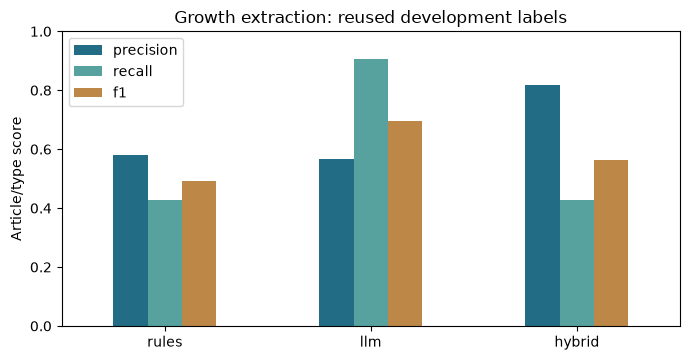

In [11]:
from growth_signals.stage import GrowthStage
from pipeline.compare import compare_growth
record = pipe.growth_records.get(company_id)
growth_results = {method: GrowthStage(llm).run(record, method, config.cutoff)
                  for method in GrowthStage.METHODS}
display(pd.DataFrame([{'method': method, 'status': value['status'],
                       'events': len(value['events']), 'excluded_pages': len(value['excluded_pages']),
                       'forecast': value['forecast']} for method, value in growth_results.items()]))
GROWTH_OUT = WORK / 'growth_recomputed'
GROWTH_OUT.mkdir(exist_ok=True)
growth_metrics = pd.DataFrame(compare_growth(pipe, WORK / 'growth_eval', GROWTH_OUT, config))
display(growth_metrics)
growth_detail = json.loads((GROWTH_OUT / 'growth_stage_results.json').read_text())
error_examples = []
for label in ('false_positives', 'false_negatives'):
    for cid, page_id, kind in growth_detail['llm_evaluation'][label][:3]:
        captured = json.loads((WORK / 'growth_eval/records/holdout_c' / (cid + '.json')).read_text())
        page = next(p for p in captured['pages'] if p['page_id'] == page_id)
        events = [e for e in growth_detail['llm'][cid]['events']
                  if e['source_url'] == page['source_url'] and e['event_type'] == kind]
        error_examples.append({'comparison_to_labels': label, 'company': captured['company_name'],
                               'event_type': kind, 'page_title': page['raw_title'],
                               'model_excerpt': events[0]['source_text'][:180] + '…' if events else '',
                               'source_url': page['source_url']})
display(pd.DataFrame(error_examples))
print('These are disagreements with the existing labels, not independently adjudicated errors.')
fig, ax = plt.subplots(figsize=(7, 3.7))
growth_metrics.set_index('method')[['precision', 'recall', 'f1']].plot.bar(ax=ax, color=['#236c85', '#57a29f', '#bd8847'])
ax.set(ylim=(0, 1), ylabel='Article/type score', xlabel='', title='Growth extraction: reused development labels')
ax.tick_params(axis='x', rotation=0)
show_figure('03_growth_extraction')

**Observed trade-off.** On these reused labels, the LLM recovered 38 of 42 article/type positives, compared with 18 for the rules, but precision remained about 57%. Taking the rules/LLM intersection increased precision to about 82% while retaining only 18 positives. The operational choice therefore depends on whether missed events or review workload is more costly; these scores do not validate a growth forecast.

The error review exposes taxonomy and coverage questions. A board appointment was classified as hiring; a forward share sale was classified as a funding round; planned infrastructure expansion appeared alongside a divestiture announcement. The missed examples include multi-story listing pages. These cases require a consistent event definition and independent adjudication before another prompt revision is evaluated.

## 7. EBITDA measurement and normalization
The main private-target route uses explicitly supplied LTM EBITDA. If component accounts are available, the measurement stage supports a net-income bridge, four discrete quarters, FY plus current YTD less prior YTD, and reviewed adjustments. Signed tax/interest amounts, periods, entities, units and accounting bases must be consistent.

An isolated public BrightView example reproduces disclosed accounts; it does not supply hidden IR inputs to private-target matching. The two LTM constructions cover July 2025–June 2026. Their 0.1 million USD difference is consistent with reported rounding. Issuer-adjusted EBITDA is shown separately; pending add-backs are not accepted as maintainable earnings.

**`provided`.** Use only explicitly supplied EBITDA with source metadata. Arithmetic and metadata checks do not establish maintainable earnings. No unavailable financial components are invented.

Sources: [SEC, Non-GAAP Financial Measures, C&DIs 100 and 103](https://www.sec.gov/rules-regulations/staff-guidance/corporation-finance-interpretations/non-gaap-financial-measures); [IPEV Valuation Guidelines (December 2025), sections 3.4 and 5.13](https://www.privateequityvaluation.com/Portals/0/Documents/Guidelines/2025%20IPEV%20Valuation%20Guidelines.pdf)

**`net_income_bridge`.** Add signed interest, tax, depreciation and amortization to net income. Arithmetic and metadata checks do not establish maintainable earnings. No unavailable financial components are invented.

Sources: [SEC, Non-GAAP Financial Measures, C&DIs 100 and 103](https://www.sec.gov/rules-regulations/staff-guidance/corporation-finance-interpretations/non-gaap-financial-measures); [IPEV Valuation Guidelines (December 2025), sections 3.4 and 5.13](https://www.privateequityvaluation.com/Portals/0/Documents/Guidelines/2025%20IPEV%20Valuation%20Guidelines.pdf)

**`four_quarters`.** Sum four nonoverlapping discrete quarters after entity, basis, units and chronology checks. Arithmetic and metadata checks do not establish maintainable earnings. No unavailable financial components are invented.

Sources: [SEC, Non-GAAP Financial Measures, C&DIs 100 and 103](https://www.sec.gov/rules-regulations/staff-guidance/corporation-finance-interpretations/non-gaap-financial-measures); [IPEV Valuation Guidelines (December 2025), sections 3.4 and 5.13](https://www.privateequityvaluation.com/Portals/0/Documents/Guidelines/2025%20IPEV%20Valuation%20Guidelines.pdf)

**`fy_plus_ytd`.** Compute fiscal year + current YTD - corresponding prior YTD, with aligned dates and definitions. Arithmetic and metadata checks do not establish maintainable earnings. No unavailable financial components are invented.

Sources: [SEC, Non-GAAP Financial Measures, C&DIs 100 and 103](https://www.sec.gov/rules-regulations/staff-guidance/corporation-finance-interpretations/non-gaap-financial-measures); [IPEV Valuation Guidelines (December 2025), sections 3.4 and 5.13](https://www.privateequityvaluation.com/Portals/0/Documents/Guidelines/2025%20IPEV%20Valuation%20Guidelines.pdf)

**`reviewed_adjustments`.** Apply only source-backed, accepted adjustments; retain all rejected or pending items. Arithmetic and metadata checks do not establish maintainable earnings. No unavailable financial components are invented.

Sources: [SEC, Non-GAAP Financial Measures, C&DIs 100 and 103](https://www.sec.gov/rules-regulations/staff-guidance/corporation-finance-interpretations/non-gaap-financial-measures); [IPEV Valuation Guidelines (December 2025), sections 3.4 and 5.13](https://www.privateequityvaluation.com/Portals/0/Documents/Guidelines/2025%20IPEV%20Valuation%20Guidelines.pdf)

,start,end,available_on,value,source_url
0,2025-07-01,2025-09-30,2025-11-19,103.7,https://s22.q4cdn.com/142468460/files/doc_fina...
1,2025-10-01,2025-12-31,2026-02-03,42.2,https://investor.brightview.com/press-releases...
2,2026-01-01,2026-03-31,2026-05-05,68.7,https://investor.brightview.com/press-releases...
3,2026-04-01,2026-06-30,2026-08-04,75.1,https://investor.brightview.com/press-releases...


,method,value,start,end,basis,currency,units,status
0,four_quarters,289.7,2025-07-01,2026-06-30,net_income_bridge,USD,millions,period_arithmetic_verified
1,fy_plus_ytd,289.8,2025-07-01,2026-06-30,net_income_bridge,USD,millions,period_arithmetic_verified


,absolute_difference_usd_million,within_reported_rounding,interpretation
0,0.1,True,Arithmetic agreement within disclosed rounding...


,year,base_ebitda,issuer_adjusted_ebitda,source_url
0,2025,306.5,352.3,https://s22.q4cdn.com/142468460/files/doc_fina...
1,2024,303.1,324.7,https://s22.q4cdn.com/142468460/files/doc_fina...


,id,amount,category,source_url,decision,reviewer,normal_recurring_cash_cost,rationale
0,transformation,26.1,transformation,https://s22.q4cdn.com/142468460/files/doc_fina...,pending,None,None,Issuer disclosure; appropriateness as maintain...
1,divestiture_gain,0.0,divestiture_gain,https://s22.q4cdn.com/142468460/files/doc_fina...,pending,None,None,Issuer disclosure; appropriateness as maintain...
2,stock_compensation,19.0,stock_compensation,https://s22.q4cdn.com/142468460/files/doc_fina...,pending,None,None,Issuer disclosure; appropriateness as maintain...
3,debt_extinguishment,0.7,debt_extinguishment,https://s22.q4cdn.com/142468460/files/doc_fina...,pending,None,None,Issuer disclosure; appropriateness as maintain...


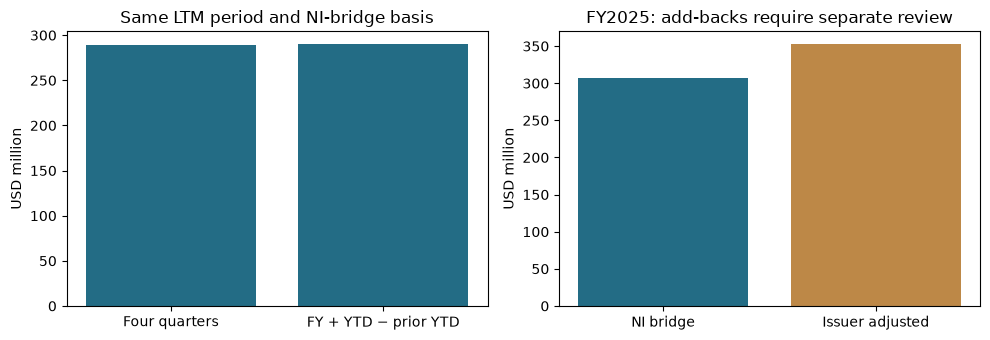

In [12]:
from valuation.period_case import public_ltm_case
from valuation.case_study import brightview_reconciliation
case = public_ltm_case(WORK / 'measurement_sources', WORK / 'measurement_sources/fy2025.txt')
display(pd.DataFrame(case['quarters'])[['start', 'end', 'available_on', 'value', 'source_url']])
measurement_rows = [{'method': key, **case[key]} for key in ('four_quarters', 'fy_plus_ytd')]
display(pd.DataFrame([{k: v for k, v in row.items() if not isinstance(v, (dict, list))} for row in measurement_rows]))
display(pd.DataFrame([case['evaluation']]))
annual = brightview_reconciliation((WORK / 'measurement_sources/fy2025.txt').read_text())
display(pd.DataFrame([{k: r[k] for k in ('year', 'base_ebitda', 'issuer_adjusted_ebitda', 'source_url')} for r in annual]))
display(pd.DataFrame(annual[0]['adjustments']))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].bar(['Four quarters', 'FY + YTD − prior YTD'], [case['four_quarters']['value'], case['fy_plus_ytd']['value']], color='#236c85')
axes[0].set(ylabel='USD million', title='Same LTM period and NI-bridge basis')
axes[1].bar(['NI bridge', 'Issuer adjusted'], [annual[0]['base_ebitda'], annual[0]['issuer_adjusted_ebitda']], color=['#236c85', '#bd8847'])
axes[1].set(ylabel='USD million', title='FY2025: add-backs require separate review')
show_figure('04_ebitda_measurement')

## 8. Valuation and sensitivity
Only positive multiples from approved public peers enter valuation. At least three valid peers are required by the declared configuration. Median, harmonic, geometric and reciprocal-rank-weighted estimates are compared without choosing the method on the target's known multiple.

The enterprise-value proxy is the estimated multiple times supplied EBITDA. It is not equity value or expected return. Cash, other claims, lease treatment, valuation dates and source definitions require further alignment. Sensitivity changes below are analyst-assumed scenarios, not probability intervals.

**`median`.** Median of positive, business-eligible public-peer EV/EBITDA multiples. Minimum three valid peers. Rank weighting is a heuristic; citations do not validate these weights. Unaligned financial bases permit a development proxy only.

Sources: [IPEV Valuation Guidelines (December 2025), sections 3.4 and 5.13](https://www.privateequityvaluation.com/Portals/0/Documents/Guidelines/2025%20IPEV%20Valuation%20Guidelines.pdf)

**`harmonic`.** Number of valid peers divided by the sum of reciprocal multiples. Minimum three valid peers. Rank weighting is a heuristic; citations do not validate these weights. Unaligned financial bases permit a development proxy only.

Sources: [Baker and Ruback (1999), Estimating Industry Multiples](https://www.hbs.edu/ris/Publication%20Files/EstimatingIndustry_b4e64d71-c8fd-4a5e-b31a-623d3a7d02bc.pdf); [Liu, Nissim and Thomas (2002), Equity Valuation Using Multiples](https://business.columbia.edu/sites/default/files-efs/imce-uploads/dnissim/publications/Equity%20Valuation%20Using%20Multiples.pdf)

**`geometric`.** Exponential of the mean log positive multiple. Minimum three valid peers. Rank weighting is a heuristic; citations do not validate these weights. Unaligned financial bases permit a development proxy only.

Sources: [IPEV Valuation Guidelines (December 2025), sections 3.4 and 5.13](https://www.privateequityvaluation.com/Portals/0/Documents/Guidelines/2025%20IPEV%20Valuation%20Guidelines.pdf)

**`rank_weighted`.** Arithmetic mean weighted by reciprocal selection rank. Minimum three valid peers. Rank weighting is a heuristic; citations do not validate these weights. Unaligned financial bases permit a development proxy only.

Sources: [Cormack, Clarke and Buettcher (2009), Reciprocal Rank Fusion](https://research.google/pubs/reciprocal-rank-fusion-outperforms-condorcet-and-individual-rank-learning-methods/)

,method,selected_peers,multiple,enterprise_value_proxy,status,release_status
0,median,3,17.052590,6493.455746,exploratory_snapshot,development_only_not_verified_fair_value
1,harmonic,3,16.336866,6220.915063,exploratory_snapshot,development_only_not_verified_fair_value
2,geometric,3,16.731577,6371.217286,exploratory_snapshot,development_only_not_verified_fair_value
3,rank_weighted,3,15.925815,6064.390921,exploratory_snapshot,development_only_not_verified_fair_value


multiple_change,-0.2,0.0,0.2
ebitda_change,,,
-0.2,4155.811678,5194.764597,6233.717516
0.0,5194.764597,6493.455746,7792.146895
0.2,6233.717516,7792.146895,9350.576274


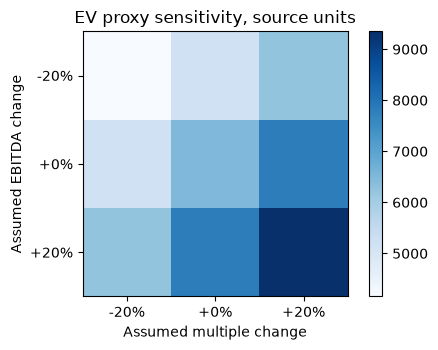

In [13]:
from dataclasses import replace
valuation_rows = []
for method in AGGREGATORS:
    report = pipe.run(COMPANY, replace(config, valuation_method=method), financial_inputs[COMPANY])
    v = report['stages']['valuation']['result']
    valuation_rows.append({'method': method, 'selected_peers': len(report['peers']),
                           'multiple': v['multiple'], 'enterprise_value_proxy': v['enterprise_value_proxy'],
                           'status': v['status'], 'release_status': v['release_status']})
display(pd.DataFrame(valuation_rows))
from valuation.measurement import valuation_scenarios
chosen = pipe.run(COMPANY, config, financial_inputs[COMPANY])
v = chosen['stages']['valuation']['result']
scenarios = valuation_scenarios(target_financials['values']['ebitda'], v['multiple'])
if scenarios:
    grid = pd.DataFrame(scenarios).pivot(index='ebitda_change', columns='multiple_change', values='ev')
    display(grid)
    fig, ax = plt.subplots(figsize=(5, 3.6))
    image = ax.imshow(grid, cmap='Blues')
    ax.set_xticks(range(len(grid.columns)), [f'{x:+.0%}' for x in grid.columns])
    ax.set_yticks(range(len(grid.index)), [f'{x:+.0%}' for x in grid.index])
    ax.set(xlabel='Assumed multiple change', ylabel='Assumed EBITDA change', title='EV proxy sensitivity, source units')
    fig.colorbar(image, ax=ax)
    show_figure('05_valuation_sensitivity')
else:
    print('Sensitivity withheld: no eligible valuation estimate for this target.')

## 9. Results and evaluation
The fixed-budget experiment applies the workflow to the ten team targets, retrieving up to five candidates and selecting three eligible peers. The primary factorial design crosses nine retrievers, direct/staged business review, eight factor subsets and four aggregators. Additional RRF-only arms compare few-shot, retrieval-assisted and saved-review policies. The result table preserves each configuration, target, selected peer count, estimate, status and error; stage objects retain the underlying evidence and intermediate output. The expanded ranked search in Section 4.2 is a separate Paylocity demonstration and has not been run across this factorial design.

The same targets remain in each denominator when a method abstains. Report coverage alongside error on scored cases; a low error among a few surviving cases is not a general improvement. One-factor comparisons fix the other choices. Unreviewed retrieval and the no-matching universe median are diagnostic controls, not approved investment recommendations. Method selection and repeated tuning on these cases require a new independent evaluation before a winner can be claimed.

**`valuation_accuracy`.** Coverage, percentage/log errors and all-target error-threshold success rates. Missing labels remain missing; post-hoc development comparisons are not independent validation.

Sources: [Hyndman and Athanasopoulos, Forecasting: Principles and Practice, accuracy measures](https://otexts.com/fpp3/toolbox.html); [Cawley and Talbot (2010), On Over-fitting in Model Selection](https://www.jmlr.org/papers/v11/cawley10a.html)

**`business_ranking`.** Precision@k and nDCG against independently graded pooled candidates. Missing labels remain missing; post-hoc development comparisons are not independent validation.

Sources: [Jarvelin and Kekalainen (2002), Cumulated Gain-Based Evaluation of IR Techniques](https://faculty.cc.gatech.edu/~zha/CS8803WST/dcg.pdf)

**`event_extraction`.** Article/type precision, recall, F1, false positives and false negatives; borderline labels excluded. Missing labels remain missing; post-hoc development comparisons are not independent validation.

Sources: [Team growth implementation and evaluation, 793cf63](https://github.com/Qual2Cast/Qual2Cast/tree/793cf63787f5abb459eff71fde26e7b0c1611eff/growth_signals)

In [14]:
RESULTS = run_comparison(WORK / 'bundle', WORK / 'recomputed_results', WORK / 'growth_eval', comparison_config)
scope = json.loads((RESULTS / 'comparison_scope.json').read_text())
display(pd.DataFrame([scope]).T.rename(columns={0: 'experiment'}))
combinations = pd.read_csv(RESULTS / 'combination_results.csv')
summary = pd.read_csv(RESULTS / 'combination_evaluation.csv')
reference = pd.read_csv(WORK / 'reference_results/combination_results.csv')
keys = ['company', 'matching_method', 'business_review_method', 'factor_method', 'valuation_method']
left = combinations.sort_values(keys).reset_index(drop=True)
right = reference.sort_values(keys).reset_index(drop=True)
pd.testing.assert_frame_equal(left[keys + ['status', 'selected_peers']], right[keys + ['status', 'selected_peers']])
np.testing.assert_allclose(left.estimate, right.estimate, equal_nan=True, rtol=1e-10, atol=1e-10)
print('All configuration outputs reproduce the embedded reference.')
selected = combinations.query("matching_method == 'rrf' and business_review_method == 'llm_staged' and factor_method == 'business_only' and valuation_method == 'median'")
display(selected[['company', 'selected_peers', 'business_eligible', 'estimate', 'observed_multiple', 'absolute_percentage_error', 'status']])
display(pd.read_csv(RESULTS / 'matching_method_evaluation.csv'))
all_reviews = pd.DataFrame(json.loads((RESULTS / 'business_stage_results.json').read_text()))
policy_matrix = all_reviews[all_reviews.method.isin(['llm_direct', 'llm_staged', 'llm_fewshot', 'llm_rag'])].pivot(index=['company', 'peer_id'], columns='method', values='status')
disagreements = policy_matrix[policy_matrix.nunique(axis=1, dropna=True).gt(1)]
display(disagreements.reset_index().assign(peer=lambda x: x.peer_id.map(company_rows.target_ciq_ticker)).drop(columns='peer_id'))
common_policies = policy_matrix.dropna()
display(pd.DataFrame({method: common_policies[method].value_counts() for method in common_policies.columns}).fillna(0))
print('The common policy comparison uses', len(common_policies), 'identical RRF candidate pairs.')
for (target, peer_id), _ in disagreements.iterrows():
    for method in policy_matrix.columns:
        matching_rows = all_reviews[(all_reviews.company == target) & (all_reviews.peer_id == peer_id) & (all_reviews.method == method)]
        if not matching_rows.empty:
            print(target, company_rows.loc[peer_id, 'target_ciq_ticker'], method, ':', matching_rows.iloc[0]['review']['rationale'])
print('These disagreements require adjudication; additional reasoning stages do not establish correctness.')

,experiment
targets,"[PCTY, BV, ROAD, FIX, BRO, ADUS, LOPE, ODFL, W..."
candidate_population,538
shortlist,5
selected_peers,3
peer_count_design,Retrieve up to five candidates and select thre...
distinct_target_peer_pairs,112
configurations,672
company_config_runs,6720
business_labels,No independent labels; human-only and saved-re...
growth_labels,Team holdout C is reused as development data f...


All configuration outputs reproduce the embedded reference.


,company,selected_peers,business_eligible,estimate,observed_multiple,absolute_percentage_error,status
2240,PCTY,3,3,17.05259,22.12710,22.933462,exploratory_snapshot
2241,BV,0,0,NaN,6.68110,NaN,abstain_insufficient_positive_multiples
2242,ROAD,1,1,NaN,16.45663,NaN,abstain_insufficient_positive_multiples
2243,FIX,2,2,NaN,22.83728,NaN,abstain_insufficient_positive_multiples
2244,BRO,2,2,NaN,17.71062,NaN,abstain_insufficient_positive_multiples
2245,ADUS,1,1,NaN,12.00902,NaN,abstain_insufficient_positive_multiples
2246,LOPE,0,0,NaN,12.51164,NaN,abstain_insufficient_positive_multiples
2247,ODFL,2,2,NaN,18.49356,NaN,abstain_insufficient_positive_multiples
2248,WING,3,3,5.81798,37.20373,84.361837,exploratory_snapshot
2249,DXPE,1,1,NaN,9.91068,NaN,abstain_insufficient_positive_multiples


,matching_method,business_review_method,targets,scored,coverage,status,median_ape,mean_ape,p90_ape,median_signed_percentage_error,mean_absolute_log_error,mae_multiple,within25_all_targets,within50_all_targets
0,cluster_eom,llm_direct,10,1,0.1,scored_development_only,22.933462,22.933462,22.933462,-22.933462,0.260501,5.074510,0.1,0.1
1,cluster_eom,llm_staged,10,1,0.1,scored_development_only,22.933462,22.933462,22.933462,-22.933462,0.260501,5.074510,0.1,0.1
2,lsa,llm_direct,10,1,0.1,scored_development_only,22.933462,22.933462,22.933462,-22.933462,0.260501,5.074510,0.1,0.1
3,lsa,llm_staged,10,1,0.1,scored_development_only,22.933462,22.933462,22.933462,-22.933462,0.260501,5.074510,0.1,0.1
4,mpnet,llm_direct,10,1,0.1,scored_development_only,22.933462,22.933462,22.933462,-22.933462,0.260501,5.074510,0.1,0.1
5,mpnet,llm_staged,10,1,0.1,scored_development_only,22.933462,22.933462,22.933462,-22.933462,0.260501,5.074510,0.1,0.1
6,mutual20,llm_direct,10,2,0.2,scored_development_only,47.710274,47.710274,67.531724,-47.710274,0.775508,16.021205,0.1,0.1
7,mutual20,llm_staged,10,2,0.2,scored_development_only,47.710274,47.710274,67.531724,-47.710274,0.775508,16.021205,0.1,0.1
8,rrf,llm_direct,10,1,0.1,scored_development_only,22.933462,22.933462,22.933462,-22.933462,0.260501,5.074510,0.1,0.1
9,rrf,llm_fewshot,10,3,0.3,scored_development_only,32.688514,46.661271,74.027172,-32.688514,0.837265,14.168510,0.1,0.2


method,company,llm_direct,llm_fewshot,llm_rag,llm_staged,peer
0,ODFL,incompatible,source_review_pass,full_scope_review_not_passed,incompatible,MRTN
1,ROAD,incompatible,source_review_pass,source_review_pass,source_review_pass,CDNL
2,WING,insufficient_evidence,source_review_pass,insufficient_evidence,source_review_pass,BDL


,llm_direct,llm_fewshot,llm_rag,llm_staged
full_scope_review_not_passed,0.0,0.0,1,0.0
incompatible,36.0,34.0,34,35.0
insufficient_evidence,1.0,0.0,1,0.0
source_review_pass,13.0,16.0,14,15.0


The common policy comparison uses 50 identical RRF candidate pairs.
ODFL MRTN llm_direct : Both operate freight carriers serving businesses’ transportation needs. However, Old Dominion’s core LTL service and Marten’s full-truckload operations represent different shipping services. Old Dominion’s truckload brokerage overlap does not establish comparable whole-company functions.
ODFL MRTN llm_fewshot : Both operate truck fleets to transport customers’ freight and supplement transportation with brokerage services. Their customers share needs for reliable goods movement, including time-sensitive and cross-border delivery. LTL versus refrigerated and dry truckload specialization changes shipment scope within the same coherent freight-carrier business; the observed additional services do not make comparability misleading.
ODFL MRTN llm_rag : Both provide road freight transportation for businesses, with carrier operations and cross-border services. LTL versus full truckload and temperature-se

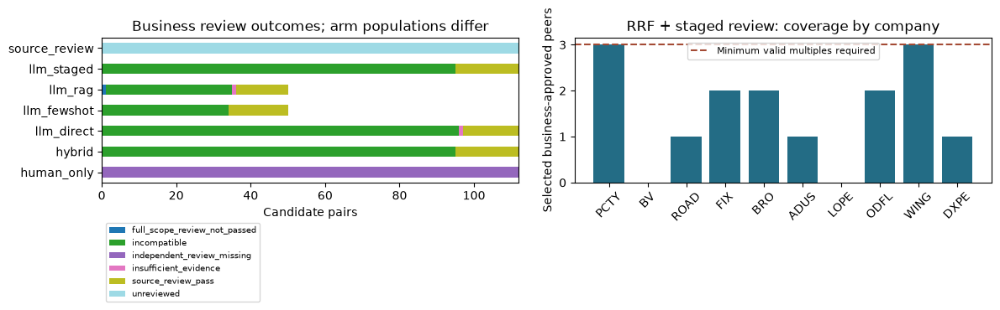

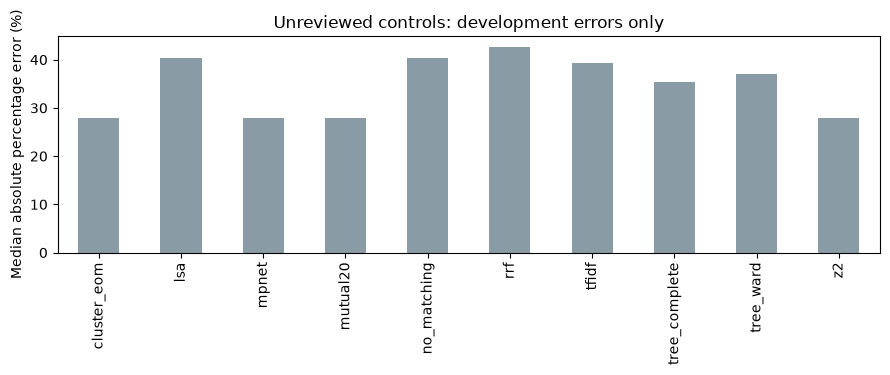

In [15]:
counts = pd.read_csv(RESULTS / 'business_evaluation.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts.pivot(index='method', columns='status', values='pairs').fillna(0).plot.barh(stacked=True, ax=axes[0], colormap='tab20')
axes[0].set(xlabel='Candidate pairs', ylabel='', title='Business review outcomes; arm populations differ')
axes[0].legend(fontsize=7, loc='upper left', bbox_to_anchor=(0, -0.25))
axes[1].bar(selected.company, selected.selected_peers, color='#236c85')
axes[1].axhline(config.min_peers, color='#a44b35', linestyle='--', label='Minimum valid multiples required')
axes[1].set(ylabel='Selected business-approved peers', title='RRF + staged review: coverage by company')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(fontsize=8)
show_figure('06_business_review_and_coverage')
controls = pd.read_csv(RESULTS / 'control_evaluation.csv')
fig, ax = plt.subplots(figsize=(9, 3.8))
controls.set_index('method').median_ape.plot.bar(ax=ax, color='#899ba4')
ax.set(ylabel='Median absolute percentage error (%)', xlabel='', title='Unreviewed controls: development errors only')
show_figure('07_control_errors')

,factor_method,business_review_method,targets,scored,coverage,status,median_ape,mean_ape,p90_ape,median_signed_percentage_error,mean_absolute_log_error,mae_multiple,within25_all_targets,within50_all_targets
0,all_three,llm_direct,10,1,0.1,scored_development_only,22.933462,22.933462,22.933462,-22.933462,0.260501,5.07451,0.1,0.1
1,all_three,llm_fewshot,10,3,0.3,scored_development_only,32.688514,46.661271,74.027172,-32.688514,0.837265,14.16851,0.1,0.2
2,all_three,llm_rag,10,1,0.1,scored_development_only,22.933462,22.933462,22.933462,-22.933462,0.260501,5.07451,0.1,0.1
3,all_three,llm_staged,10,2,0.2,scored_development_only,53.647649,53.647649,78.218999,-53.647649,1.057978,18.23013,0.1,0.1
4,all_three,source_review,10,0,0.0,no_valid_pairs,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0
5,business_only,llm_direct,10,1,0.1,scored_development_only,22.933462,22.933462,22.933462,-22.933462,0.260501,5.07451,0.1,0.1
6,business_only,llm_fewshot,10,3,0.3,scored_development_only,32.688514,46.661271,74.027172,-32.688514,0.837265,14.16851,0.1,0.2
7,business_only,llm_rag,10,1,0.1,scored_development_only,22.933462,22.933462,22.933462,-22.933462,0.260501,5.07451,0.1,0.1
8,business_only,llm_staged,10,2,0.2,scored_development_only,53.647649,53.647649,78.218999,-53.647649,1.057978,18.23013,0.1,0.1
9,business_only,source_review,10,0,0.0,no_valid_pairs,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0


,valuation_method,business_review_method,targets,scored,coverage,status,median_ape,mean_ape,p90_ape,median_signed_percentage_error,mean_absolute_log_error,mae_multiple,within25_all_targets,within50_all_targets
0,geometric,llm_direct,10,1,0.1,scored_development_only,24.384229,24.384229,24.384229,-24.384229,0.279505,5.395523,0.1,0.1
1,geometric,llm_fewshot,10,3,0.3,scored_development_only,45.063177,50.426690,74.478767,-45.063177,0.861346,14.724704,0.1,0.2
2,geometric,llm_rag,10,1,0.1,scored_development_only,24.384229,24.384229,24.384229,-24.384229,0.279505,5.395523,0.1,0.1
3,geometric,llm_staged,10,2,0.2,scored_development_only,53.108447,53.108447,76.087821,-53.108447,0.992525,17.920163,0.1,0.1
4,geometric,source_review,10,0,0.0,no_valid_pairs,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0
5,harmonic,llm_direct,10,1,0.1,scored_development_only,26.168067,26.168067,26.168067,-26.168067,0.303379,5.790234,0.0,0.1
6,harmonic,llm_fewshot,10,3,0.3,scored_development_only,47.814442,52.181808,75.613221,-47.814442,0.900105,15.116437,0.0,0.2
7,harmonic,llm_rag,10,1,0.1,scored_development_only,26.168067,26.168067,26.168067,-26.168067,0.303379,5.790234,0.0,0.1
8,harmonic,llm_staged,10,2,0.2,scored_development_only,54.365491,54.365491,76.923431,-54.365491,1.024975,18.253359,0.0,0.1
9,harmonic,source_review,10,0,0.0,no_valid_pairs,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0


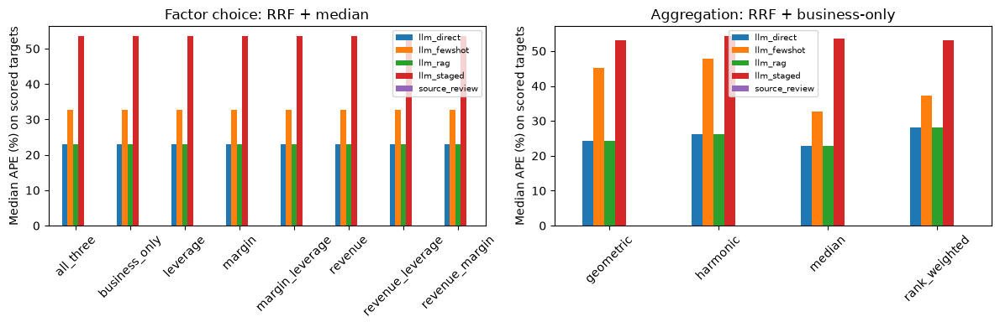

All 672 configurations, including abstentions: company_workflow_7868828a683a\recomputed_results\20261020T034620Z-8f8ee0\combination_evaluation.csv
Factor choice changes the estimate in 58 of 116 groups with at least one estimate.


,matching_method,business_review_method,factor_method,valuation_method,common_scored,common_companies,method_coverage,reference_coverage,common_median_ape,reference_common_median_ape,mean_paired_ape_change_pp
262,rrf,llm_direct,business_only,median,1,PCTY,0.1,0.2,22.933462,22.933462,0.0
294,rrf,llm_fewshot,business_only,median,2,"PCTY, WING",0.3,0.2,53.647649,53.647649,0.0
326,rrf,llm_rag,business_only,median,1,PCTY,0.1,0.2,22.933462,22.933462,0.0
358,rrf,llm_staged,business_only,median,2,"PCTY, WING",0.2,0.2,53.647649,53.647649,0.0
390,rrf,source_review,business_only,median,0,NaN,0.0,0.2,NaN,NaN,NaN


Paired comparison reference: RRF, staged review, business-only factors, median. APE is in percent; negative paired change indicates lower error on the common cases only.


In [16]:
factor_summary = pd.read_csv(RESULTS / 'factor_method_evaluation.csv')
valuation_summary = pd.read_csv(RESULTS / 'valuation_method_evaluation.csv')
display(factor_summary)
display(valuation_summary)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, frame, field, title in [(axes[0], factor_summary, 'factor_method', 'Factor choice: RRF + median'),
                               (axes[1], valuation_summary, 'valuation_method', 'Aggregation: RRF + business-only')]:
    frame.pivot(index=field, columns='business_review_method', values='median_ape').plot.bar(ax=ax)
    ax.set(ylabel='Median APE (%) on scored targets', xlabel='', title=title)
    ax.tick_params(axis='x', rotation=45)
    ax.legend(fontsize=7)
show_figure('08_factor_and_valuation_comparison')
print(f'All {len(summary)} configurations, including abstentions: {RESULTS / "combination_evaluation.csv"}')
factor_groups = combinations.groupby(['company', 'matching_method', 'business_review_method', 'valuation_method']).estimate.nunique()
print('Factor choice changes the estimate in', int((factor_groups > 1).sum()), 'of', int((factor_groups > 0).sum()), 'groups with at least one estimate.')
paired = pd.read_csv(RESULTS / 'paired_method_evaluation.csv')
display(paired.query("matching_method == 'rrf' and factor_method == 'business_only' and valuation_method == 'median'"))
print('Paired comparison reference: RRF, staged review, business-only factors, median. APE is in percent; negative paired change indicates lower error on the common cases only.')

### 9.1. Assessment and independent review
The automated assessment separates engineering validity, business relevance and economic accuracy. Passing schema checks and reproducing outputs establish execution, not fair value. Source examples expose role mismatches; error and coverage tables show the cost of stricter review. Growth extraction is evaluated separately from forecasting. The EBITDA case validates arithmetic on disclosed inputs, not the acceptability of all add-backs.

Independent reviewers should judge the pooled candidate list without seeing valuation error or model verdicts. Grades are **0: incompatible**, **1: weak/partial overlap**, **2: plausible comparable with material differences**, **3: strong comparable**; insufficient evidence stays blank with a reason. Record sources, all four criteria, business-scope differences and reviewer identity. Grade ≥2 is the declared positive threshold for precision@k. nDCG uses the entire judged pool. Model decisions never populate these labels.

**Valuation finding.** The fixed RRF/staged/median route produces estimates for only Paylocity and Wingstop: absolute percentage errors of 22.9% and 84.4%, respectively. The other eight cases abstain under the three-peer requirement. Direct or retrieval-assisted review reduces coverage further; lower conditional error on fewer cases is not evidence of superiority. Business review alone does not explain valuation premiums, and broad restaurant comparability does not settle franchise mix or economic differences.

Remaining requirements are independent peer adjudication, an untouched company sample after freezing methods, verified peer/target financial periods and definitions, broader evidence coverage, and point-in-time growth labels. These gaps are not resolved by changing the model name.

In [17]:
human_queue = pd.read_csv(RESULTS / 'independent_human_review.csv')
assert human_queue.grade_0_to_3.isna().all()
display(human_queue[['target', 'peer', 'reviewer', 'grade_0_to_3', 'rationale']].head(10))
review_import = pipe.import_human_reviews(RESULTS / 'independent_human_review.csv')
assert review_import['status'] == 'no_completed_reviews'
print('Human-review import:', review_import['status'])
# For a completed independent review, import its CSV and use business_review_method='human_only'.
display(pd.DataFrame([pipe.evaluation.run('business_ranking', ranked_ids=candidate_tables['rrf'].peer_id.tolist(), pooled_grades={}, k=5)]))
assessment = pd.DataFrame([
    {'dimension': 'Reproducibility', 'finding': f'{len(combinations)} configuration-target outputs reproduced from fixed evidence and model responses.'},
    {'dimension': 'Business relevance', 'finding': 'Four-criterion source review precedes every financial ranking; independent accuracy labels remain absent.'},
    {'dimension': 'Fixed-budget coverage', 'finding': f'{selected.estimate.notna().sum()}/{len(selected)} targets have a development multiple; inspect abstentions explicitly.'},
    {'dimension': 'Progressive ranked search', 'finding': f'{COMPANY}: {search["business_approved"]} approved among {search["reviewed_candidates"]} reviewed; {search["unreviewed_candidates"]} remain unreviewed. Stop: {search["status"]}.'},
    {'dimension': 'Factor/method choice', 'finding': 'Compare error together with coverage on the common cases; no independent winner is established.'},
    {'dimension': 'Growth', 'finding': 'Extraction scores use reused single-annotator labels; no forecast or valuation premium is validated.'},
    {'dimension': 'Measurement', 'finding': f'LTM construction difference: {case["evaluation"]["absolute_difference_usd_million"]:.1f} million USD; add-back review remains separate.'},
    {'dimension': 'Private-company applicability', 'finding': 'Input contract supports private sources; real private-company validation and financial alignment remain incomplete.'}
])
display(assessment)
assessment.to_csv(RESULTS / 'assessment.csv', index=False)
exported = export_reports(RESULTS)
print('Full results, source-linked company reports and blank human-review queue:', RESULTS)
print('Charts:', FIGURES)
pipe.close()

,target,peer,reviewer,grade_0_to_3,rationale
0,PCTY,ADP,NaN,NaN,NaN
1,PCTY,INTU,NaN,NaN,NaN
2,PCTY,HURN,NaN,NaN,NaN
3,PCTY,PAYC,NaN,NaN,NaN
4,PCTY,BBSI,NaN,NaN,NaN
5,PCTY,ASUR,NaN,NaN,NaN
6,PCTY,FA,NaN,NaN,NaN
7,BV,HQY,NaN,NaN,NaN
8,BV,GRBK,NaN,NaN,NaN
9,BV,TTC,NaN,NaN,NaN


Human-review import: no_completed_reviews


,status,ndcg,precision
0,not_computed_no_independent_labels,None,None


,dimension,finding
0,Reproducibility,6720 configuration-target outputs reproduced f...
1,Business relevance,Four-criterion source review precedes every fi...
2,Fixed-budget coverage,2/10 targets have a development multiple; insp...
3,Progressive ranked search,PCTY: 3 approved among 50 reviewed; 487 remain...
4,Factor/method choice,Compare error together with coverage on the co...
5,Growth,Extraction scores use reused single-annotator ...
6,Measurement,LTM construction difference: 0.1 million USD; ...
7,Private-company applicability,Input contract supports private sources; real ...


Full results, source-linked company reports and blank human-review queue: company_workflow_7868828a683a\recomputed_results\20261020T034620Z-8f8ee0
Charts: company_workflow_7868828a683a\figures
